In [13]:
# Initialisation

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import umap

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

SEED = 0
SAMPLES_PER_CLASS = 500
CLASS_IDS = list(range(10))

np.random.seed(SEED)
torch.manual_seed(SEED)

Device: cuda


In [3]:
# HuggingFace login to stream ImageNet
# Run this exactly once to get the image in the current working directory

from huggingface_hub import login
login()

from datasets import load_dataset
from pathlib import Path
from collections import Counter

# Load ImageNet training data without downloading
stream = load_dataset("ILSVRC/imagenet-1k", split="train", streaming=True)
output_dir = Path("./imagenet-first10")
counts = Counter()

for example in stream:
    label = int(example["label"])
    # Keep only the first 10 classes
    if not 0 <= label < 10:
        continue
    if counts[label] >= SAMPLES_PER_CLASS:
        continue
    # Create class directories 000, 001, 002...
    class_dir = output_dir / f"{label:03d}"
    class_dir.mkdir(parents=True, exist_ok=True)
    image = example["image"].convert("RGB")
    image.save(class_dir / f"{counts[label]:05d}.jpg", format="JPEG")
    counts[label] += 1
    if all(counts[c] == SAMPLES_PER_CLASS for c in range(10)):
        break
print("Images saved per class:", dict(sorted(counts.items())))
if any(counts[c] != SAMPLES_PER_CLASS for c in range(10)):
    raise RuntimeError("Not all classes reached 500 images")

/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/PIL/TiffImagePlugin.py:982: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Images saved per class: {0: 500, 1: 500, 2: 500, 3: 500, 4: 500, 5: 500, 6: 500, 7: 500, 8: 500, 9: 500}


MNIST: (5000, 784)
ImageNet: (5000, 12288)


/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initializa

MNIST embedding: (5000, 2)
ImageNet embedding: (5000, 2)


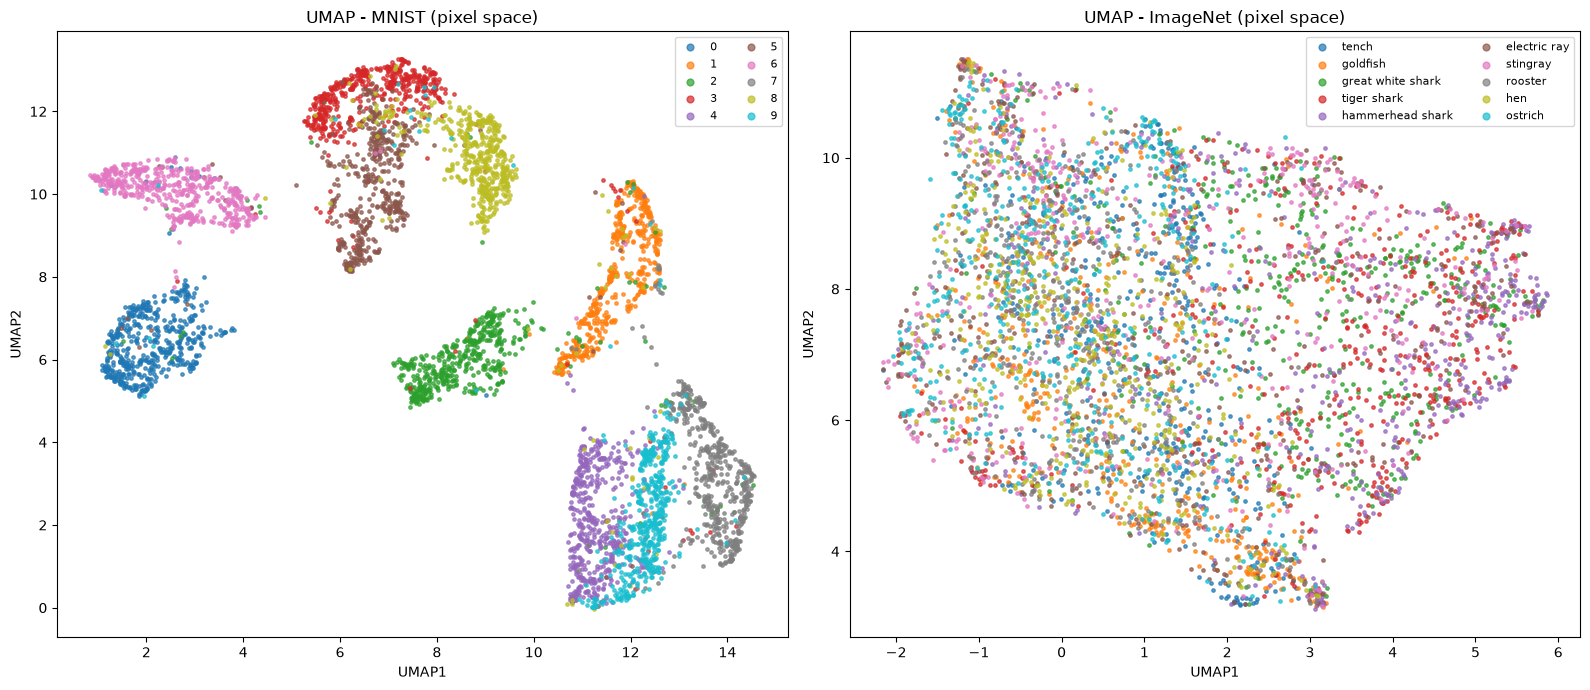

In [14]:
# Experiment 0

mnist = datasets.MNIST(root="./data", train=True, download=True, transform=transforms.ToTensor())

imagenet_transform = transforms.Compose([
  transforms.Resize((64,64)),
  transforms.ToTensor()
])
imagenet = datasets.ImageFolder(root="./imagenet-first10", transform=imagenet_transform)


def balanced_subset(dataset, class_ids, n_per_class=500, seed=0):
  rng = np.random.default_rng(seed)
  targets = np.asarray(dataset.targets)
  selected_indices = []
  for class_id in class_ids:
    candidates = np.flatnonzero(targets == class_id)
    if len(candidates) < n_per_class:
      raise ValueError(f"Class {class_id} has only {len(candidates)} images.")
    indices = rng.choice(candidates, size=n_per_class, replace=False)
    selected_indices.extend(indices.tolist())
  rng.shuffle(selected_indices)
  return Subset(dataset, selected_indices)

mnist_subset = balanced_subset(mnist, CLASS_IDS, SAMPLES_PER_CLASS, SEED)

imagenet_subset = balanced_subset(imagenet, CLASS_IDS, SAMPLES_PER_CLASS, SEED)

def extract_pixels(dataset, batch_size=128):
  loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
  features=[]
  labels=[]
  for images, targets in loader:
    flattened = images.flatten(start_dim=1)
    features.append(flattened.numpy())
    labels.append(targets.numpy())
  X = np.concatenate(features, axis=0).astype(np.float32)
  y = np.concatenate(labels, axis=0)
  return X, y

X_mnist, y_mnist = extract_pixels(mnist_subset)
X_imagenet, y_imagenet = extract_pixels(imagenet_subset)

print("MNIST:", X_mnist.shape)
print("ImageNet:", X_imagenet.shape)

def run_umap(X, n_neighbors=15, min_dist=0.1, seed=0):
  reducer = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=2, metric="euclidean", random_state=seed, low_memory=True)
  embedding = reducer.fit_transform(X)
  return embedding

embedding_mnist = run_umap(X_mnist)
embedding_imagenet = run_umap(X_imagenet)
print("MNIST embedding:", embedding_mnist.shape)
print("ImageNet embedding:", embedding_imagenet.shape)

def plot_umap(embedding, labels, class_names, title, ax):
  colors = plt.get_cmap("tab10")
  for class_id in np.unique(labels):
    mask = labels == class_id
    ax.scatter(embedding[mask, 0], embedding[mask, 1], color=colors(int(class_id)), label=class_names[int(class_id)], s=6, alpha=0.7, rasterized=True)
  ax.set_title(title)
  ax.set_xlabel("UMAP1")
  ax.set_ylabel("UMAP2")
  ax.legend(markerscale=2, fontsize=8, ncol=2)

mnist_names = [str(i) for i in range(10)]
imagenet_names = ["tench", "goldfish", "great white shark", "tiger shark", "hammerhead shark", "electric ray", "stingray", "rooster", "hen", "ostrich"]
fig, axes = plt.subplots(1, 2, figsize=(16,7))
plot_umap(embedding_mnist, y_mnist, mnist_names, "UMAP - MNIST (pixel space)", axes[0])
plot_umap(embedding_imagenet, y_imagenet, imagenet_names, "UMAP - ImageNet (pixel space)", axes[1])
plt.tight_layout()
plt.savefig("umap_pixel_space.png", dpi=200, bbox_inches="tight")
plt.show()

# Expérience 0

En projetant les données MNIST d'entraînement avec UMAP, on peut observer que la plupart des classes sont déjà bien séparées: on peut supposer que le jeu de données possède une certaine structure dans le domaine des pixels. Cependant, certaines classes sont tout de même très proches (3, 5 et 8, et 4, 9 et 7): la projection UMAP ne classifiant pas, elle préserve simplement les relations de voisinage dans les données. C'est particulièrement visible pour 3, 5, et 8 qui, manuscrits, peuvent être assez similaires visuellement. On ne peut donc pas tirer une conclusion véritablement sémantique de UMAP.

Pour ImageNet, cependant, il n'y a pas de séparation nette entre les classes. Les exemples sont mélangés dans une distribution uniforme. Ceci peut s'expliquer par la nature des données: là où MNIST contient des images en niveaux de gris, avec un fond toujours noir, les données d'ImageNet sont sujettes à beaucoup plus de variation. Deux images de la même catégories peuvent avoir de nombreuses différences au niveau des pixels (arrière-plan, luminosité, position de l'objet, échelle etc.). Inversement, des images de deux catégories différentes peuvent être similaires au niveau des pixels sans représenter le même objet (exemple: deux espèces de requins différentes avec le même fond bleu de l'océan).

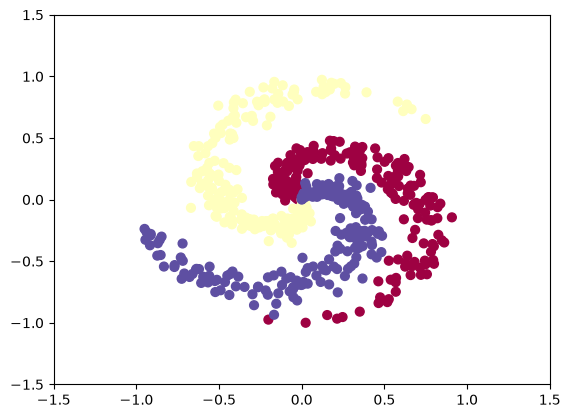

Final: (2000, 0.12572433054447174, 0.9625000357627869, 0.9583333730697632)


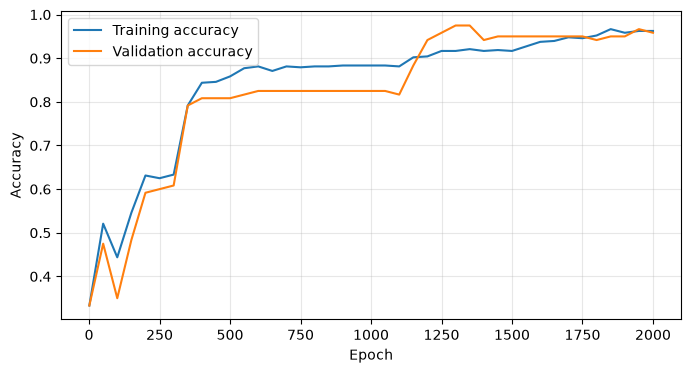

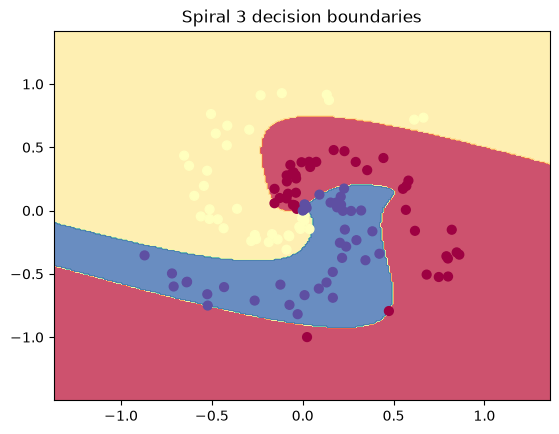

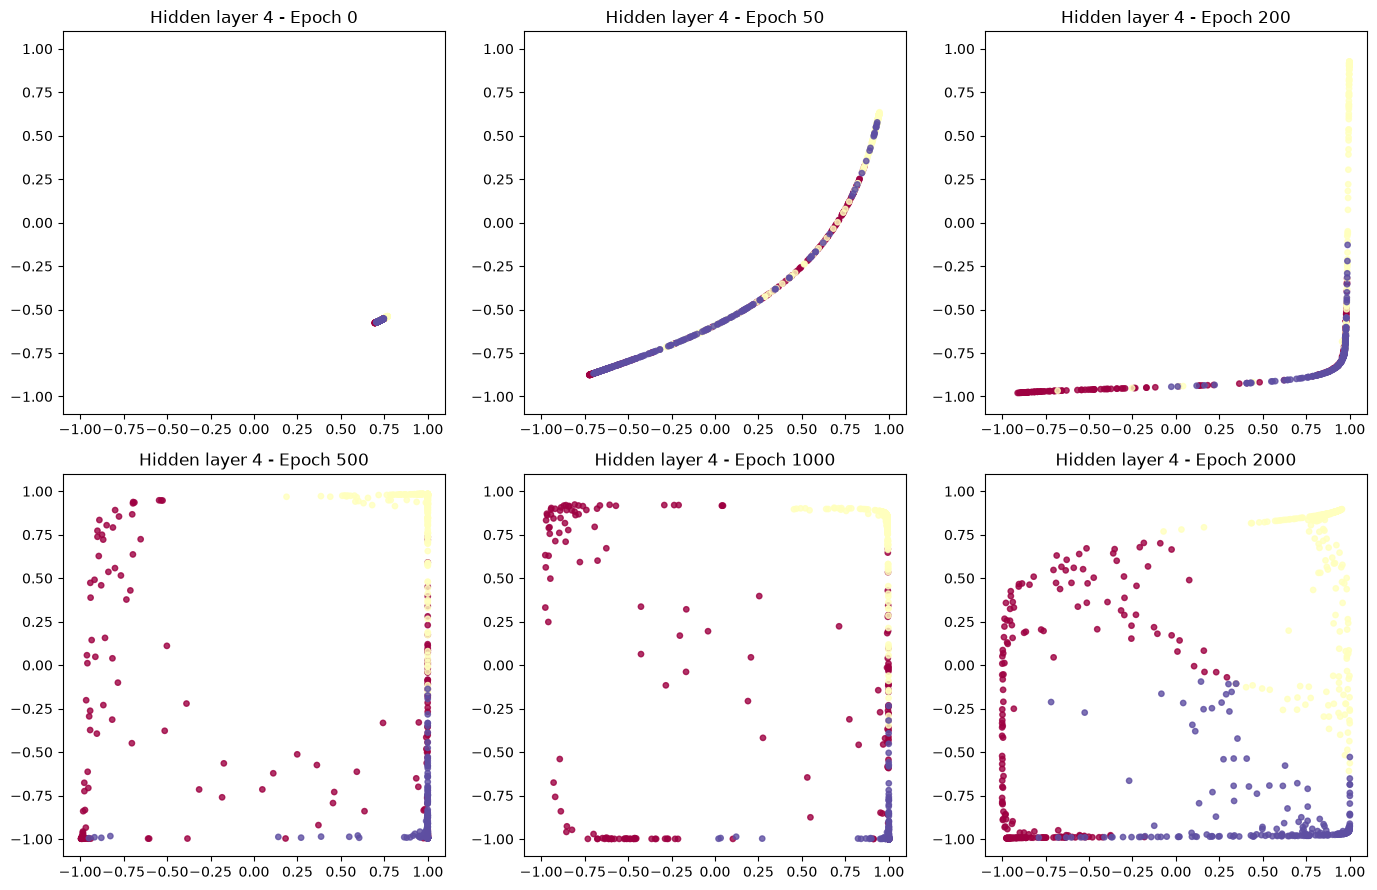

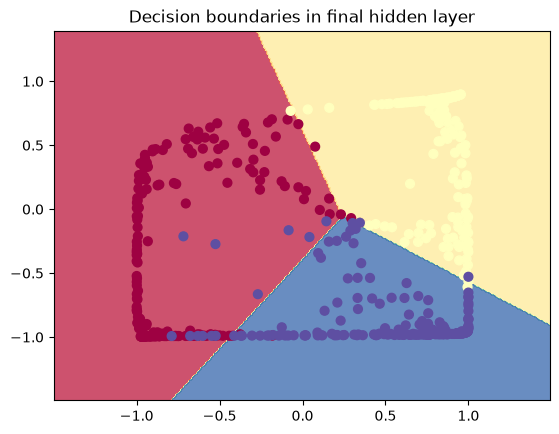

In [15]:
# Experiment 1

def toy_spiral3(N=200, K=3, D=2):
    # N points per class, D dimensions, K classes, arranged as three interleaved arms
    np.random.seed(0)
    X = np.zeros((N * K, D))
    y = np.zeros(N * K, dtype='uint8')
    for j in range(K):
        ix = range(N * j, N * (j + 1))
        r = np.linspace(0.0, 1, N)                                    # radius
        t = 5 + np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.3   # angle
        X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
        y[ix] = j
    return X, y


def toy_plot(X, y):
    plt.figure()
    plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
    plt.xlim([-1.5, 1.5])
    plt.ylim([-1.5, 1.5])


def plot_decision_boundaries(X, y, f, title=""):
    h = 0.01
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = f(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure()
    plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title(title)
    plt.show()

# Generate spiral
X, y = toy_spiral3()
# 80/20 training-validation split
rng = np.random.default_rng(SEED)
train_idx, val_idx = [], []
for c in np.unique(y):
  indices = rng.permutation(np.flatnonzero(y == c))
  cut = int(0.8 * len(indices))
  train_idx.extend(indices[:cut])
  val_idx.extend(indices[cut:])
X_train = torch.tensor(X[train_idx], dtype=torch.float32, device=device)
y_train = torch.tensor(y[train_idx], dtype=torch.long, device=device)
X_val = torch.tensor(X[val_idx], dtype=torch.float32, device=device)
y_val = torch.tensor(y[val_idx], dtype=torch.long, device=device)
toy_plot(X, y)
plt.show()

class SpiralNet(nn.Module):
  def __init__(self, n_hidden=3):
    super().__init__()
    self.hidden = nn.ModuleList()
    for _ in range(n_hidden):
      self.hidden.append(nn.Sequential(nn.Linear(2, 2), nn.Tanh()))
    self.output = nn.Linear(2, 3)

  def project(self, x, layer_index):
    """
    layer_index = 0: original input
    layer_index = 1: first hidden layer
    layer_index = 2: second hidden layer
    etc.
    """
    if not 0 <= layer_index <= len(self.hidden):
      raise ValueError("Invalid layer index")
    for layer in self.hidden[:layer_index]:
      x = layer(x)
    return x

  def forward(self, x):
    x = self.project(x, len(self.hidden))
    return self.output(x)

# Model setup
N_HIDDEN = 4
EPOCHS = 2000
LEARNING_RATE = 0.01
WEIGHT_DECAY = 1e-5

CHECKPOINTS= [0, 50, 200, 500, 1000, 2000]
model = SpiralNet(n_hidden=N_HIDDEN).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

# For history
def save_state(model):
  return {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}

states = {0: save_state(model)}
history = []
for epoch in range(1, EPOCHS + 1):
  model.train()
  optimizer.zero_grad()
  logits = model(X_train)
  loss = criterion(logits, y_train)
  loss.backward()
  optimizer.step()
  if epoch in CHECKPOINTS:
    states[epoch] = save_state(model)
  if epoch % 50 == 0 or epoch == 1:
    model.eval()
    with torch.no_grad():
      train_acc = ((model(X_train).argmax(dim=1) == y_train).float().mean().item())
      val_acc = ((model(X_val).argmax(dim=1) == y_val).float().mean().item())
    history.append((epoch, loss.item(), train_acc, val_acc))
print("Final:", history[-1])

# CHeck training performance
history_array = np.array(history)
plt.figure(figsize=(8,4))
plt.plot(history_array[:, 0], history_array[:, 2], label="Training accuracy")
plt.plot(history_array[:, 0], history_array[:, 3], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

def predict_classes(X_numpy):
  model.eval()
  with torch.no_grad():
    inputs = torch.tensor(X_numpy, dtype=torch.float32, device=device)
    logits = model(inputs)
    predictions = logits.argmax(dim=1)
  return predictions.cpu().numpy()

plot_decision_boundaries(X[val_idx], y[val_idx], predict_classes, title="Spiral 3 decision boundaries")

# Visualisation of a hidden layer
VIS_LAYER = 4 # 0 = input, 1..N_HIDDEN = hidden layers
X_all = torch.tensor(X, dtype=torch.float32, device=device)
view_model = SpiralNet(n_hidden=N_HIDDEN).to(device)
fig, axes = plt.subplots(2, 3, figsize=(14,9))
for ax, (epoch, weights) in zip(axes.flat, sorted(states.items())):
  view_model.load_state_dict(weights)
  view_model.eval()
  with torch.no_grad():
    projection = view_model.project(X_all, VIS_LAYER).cpu().numpy()
  ax.scatter(projection[:, 0], projection[:, 1], c=y, cmap=plt.cm.Spectral, vmin=0, vmax=2, s=15, alpha=0.8)
  ax.set_xlim(-1.1, 1.1)
  ax.set_ylim(-1.1, 1.1)
  ax.set_aspect("equal", adjustable="box")
  ax.set_title(f"Hidden layer {VIS_LAYER} - Epoch {epoch}")
plt.tight_layout()
plt.show()

model.eval()
with torch.no_grad():
  H = model.project(X_all, N_HIDDEN).cpu().numpy()

def predict_in_hidden_space(H_numpy):
  with torch.no_grad():
    h = torch.tensor(H_numpy, dtype=torch.float32, device=device)
    logits = model.output(h)
    return logits.argmax(dim=1).cpu().numpy()

plot_decision_boundaries(H, y, predict_in_hidden_space, title="Decision boundaries in final hidden layer")

# Expérience 1

En utilisant UMAP, nous pouvons observer l'évolution de la représentation apprise à chaque couche, et l'évolution de la dernière couche (ici, la quatrième) est particulièrement intéressante: on peut voir que la projection des points tend vers une représentation mieux linéairement séparable des points. En fonction de comment le modèle apprend, on peut même se retrouver avec une division 1/3 - 1/3 - 1/3 du plan pour chaque classe.

On utilise deux neurones par couche car cela produit une représentation qui est déjà en deux dimensions, et donc plus simple à visualiser. On aurait également pu utiliser UMAP si chaque couche possèdait plus de deux neurones, mais cette configuration facilite la visualisation.

Random   | Epoch 00 |train loss 3.1618, acc 10.00% |val loss 3.1624, acc 10.00%
Random   | Epoch 01 |train loss 0.1355, acc 95.75% |val loss 0.1291, acc 95.75%
Random   | Epoch 02 |train loss 0.3688, acc 88.89% |val loss 0.3640, acc 88.30%
Random   | Epoch 03 |train loss 0.0701, acc 98.03% |val loss 0.1043, acc 97.05%
Random   | Epoch 04 |train loss 0.0520, acc 98.48% |val loss 0.1027, acc 96.95%
Random   | Epoch 05 |train loss 0.0197, acc 99.40% |val loss 0.0483, acc 98.30%
Random   | Epoch 06 |train loss 0.0229, acc 99.17% |val loss 0.0613, acc 97.75%
Random   | Epoch 07 |train loss 0.1222, acc 96.63% |val loss 0.1635, acc 96.15%
Random   | Epoch 08 |train loss 0.0103, acc 99.64% |val loss 0.0408, acc 98.90%
ImageNet | Epoch 00 |train loss 2.3101, acc 14.60% |val loss 2.3101, acc 13.90%
ImageNet | Epoch 01 |train loss 0.0987, acc 96.94% |val loss 0.1034, acc 97.00%
ImageNet | Epoch 02 |train loss 0.0505, acc 98.38% |val loss 0.0784, acc 97.80%
ImageNet | Epoch 03 |train loss 0.0402, 

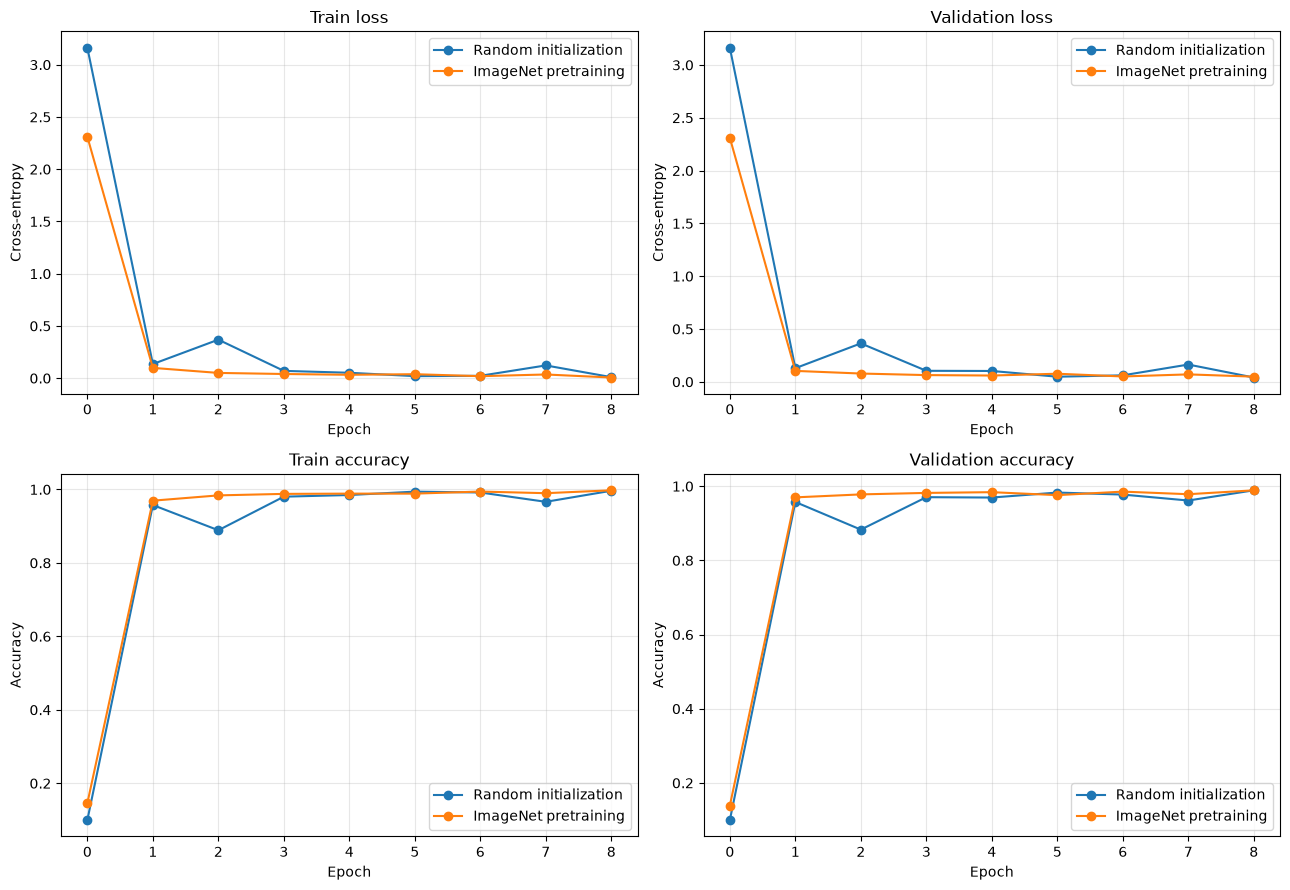

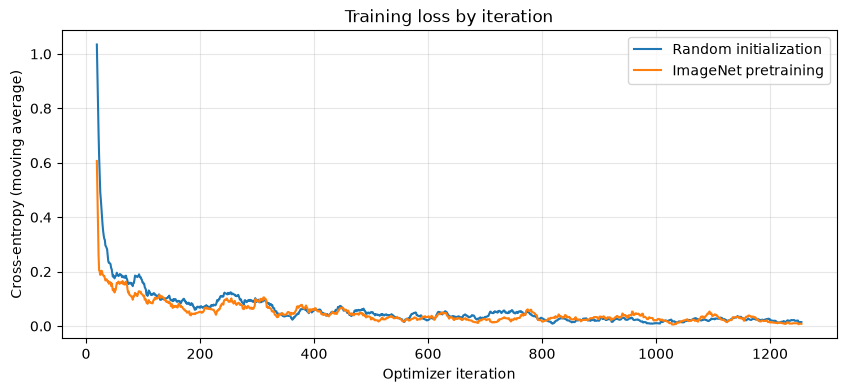

Features before flatten: (2000, 512) (2000, 512)


/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initializa

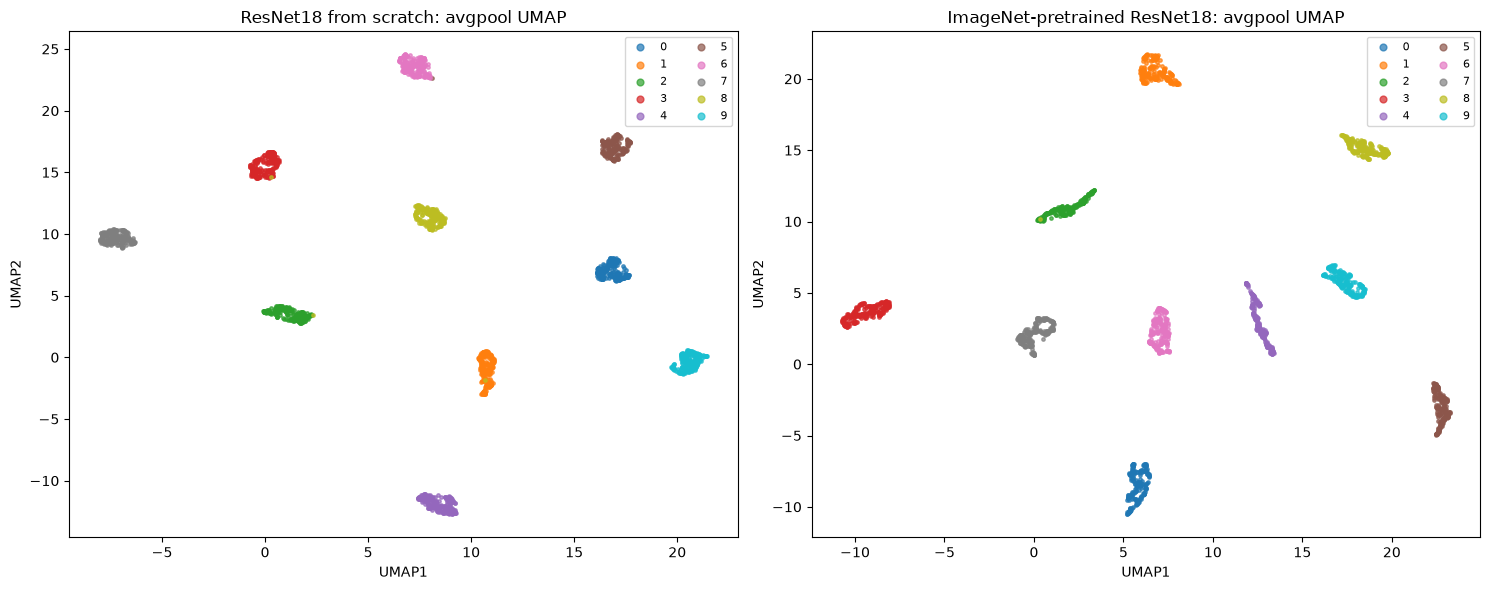

In [16]:
# Experiment 2

from torchvision import models

# Config
RESNET_IMAGE_SIZE=128
RESNET_TRAIN_PER_CLASS=1000
RESNET_VAL_PER_CLASS=200
RESNET_BATCH_SIZE=64
RESNET_EPOCHS=8
RESNET_LR=1e-3
RESNET_WEIGHT_DECAY=1e-4
RESNET_UMAP_PER_CLASS=200

# Dataset preparations (same images and preprocessing for both versions)
resnet_transform = transforms.Compose([
    transforms.Resize((RESNET_IMAGE_SIZE, RESNET_IMAGE_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
resnet_mnist = datasets.MNIST(root="./data", train=True, download=True, transform=resnet_transform)
resnet_rng = np.random.default_rng(SEED)
resnet_targets = np.asarray(resnet_mnist.targets)
resnet_train_ids, resnet_val_ids = [], []

for cls in range(10):
  ids = resnet_rng.permutation(np.flatnonzero(resnet_targets == cls))
  count = RESNET_TRAIN_PER_CLASS + RESNET_VAL_PER_CLASS
  assert len(ids) >= count, f"Not enough images of class {cls}"
  resnet_train_ids.extend(ids[:RESNET_TRAIN_PER_CLASS].tolist())
  resnet_val_ids.extend(ids[RESNET_TRAIN_PER_CLASS:count].tolist())

resnet_train_dataset = Subset(resnet_mnist, resnet_train_ids)
resnet_val_dataset = Subset(resnet_mnist, resnet_val_ids)
resnet_pin = (device.type == "cuda")

# Non-shuffled loaders for full dataset metrics
resnet_train_eval_loader = DataLoader(resnet_train_dataset, batch_size=RESNET_BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=resnet_pin)
resnet_val_loader = DataLoader(resnet_val_dataset, batch_size=RESNET_BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=resnet_pin)

# Network and evaluation
def make_resnet18(pretrained):
  weights = models.ResNet18_Weights.DEFAULT if pretrained else None
  net = models.resnet18(weights=weights)
  net.fc = nn.Linear(net.fc.in_features, 10)
  return net.to(device)

# This line prevents PyTorch from doing graph computations during training,
# saving on computing time
@torch.inference_mode()
def evaluate_resnet(net, loader):
  net.eval()
  total_loss, correct, n = 0.0, 0, 0
  loss_fn = nn.CrossEntropyLoss()
  for xb, yb in loader:
    xb = xb.to(device, non_blocking=True)
    yb = yb.to(device, non_blocking=True)
    with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
      logits = net(xb)
      loss = loss_fn(logits, yb)
    total_loss += loss.item() * len(yb)
    correct += (logits.argmax(dim=1) == yb).sum().item()
    n += len(yb)
  return total_loss / n, correct / n

def train_resnet18(pretrained):
  net = make_resnet18(pretrained)
  shuffle_rng = torch.Generator().manual_seed(SEED)
  train_loader = DataLoader(resnet_train_dataset, batch_size=RESNET_BATCH_SIZE, shuffle=True, generator=shuffle_rng, num_workers=2, pin_memory=resnet_pin)
  optimizer = torch.optim.AdamW(net.parameters(), lr=RESNET_LR, weight_decay=RESNET_WEIGHT_DECAY)
  scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
  loss_fn = nn.CrossEntropyLoss()
  hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "batch_loss": []}
  # Include epoch 0 to compare initial losses
  for epoch in range(RESNET_EPOCHS + 1):
    if epoch > 0:
      net.train()
      for xb, yb in train_loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=(device.type=="cuda")):
          logits = net(xb)
          loss = loss_fn(logits, yb)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        hist["batch_loss"].append(loss.item())
    train_loss, train_acc = evaluate_resnet(net, resnet_train_eval_loader)
    val_loss, val_acc = evaluate_resnet(net, resnet_val_loader)
    hist["train_loss"].append(train_loss)
    hist["train_acc"].append(train_acc)
    hist["val_loss"].append(val_loss)
    hist["val_acc"].append(val_acc)
    print(f"{'ImageNet' if pretrained else 'Random':8s} | "
          f"Epoch {epoch:02d} |"
          f"train loss {train_loss:.4f}, acc {train_acc:.2%} |"
          f"val loss {val_loss:.4f}, acc {val_acc:.2%}")
  return net, hist

resnet_random_model, resnet_random_hist = train_resnet18(pretrained=False)
resnet_pretrained_model, resnet_pretrained_hist = train_resnet18(pretrained=True)

# Loss and accuracy curves
resnet_epochs = np.arange(RESNET_EPOCHS + 1)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for hist, label in [(resnet_random_hist, "Random initialization"), (resnet_pretrained_hist, "ImageNet pretraining")]:
  for ax, field in [(axes[0, 0], "train_loss"), (axes[0,1], "val_loss"), (axes[1, 0], "train_acc"), (axes[1, 1], "val_acc")]:
    ax.plot(resnet_epochs, hist[field], marker="o", label=label)
for ax, title in zip(axes.flat, ["Train loss", "Validation loss", "Train accuracy", "Validation accuracy"]):
  ax.set_title(title)
  ax.set_xlabel("Epoch")
  ax.set_ylabel("Accuracy" if "accuracy" in title.lower() else "Cross-entropy")
  ax.grid(alpha=0.3)
  ax.legend()
plt.tight_layout()
plt.show()

# Loss by iteration (smoothed to reduce per-batch noise)
plt.figure(figsize=(10, 4))
for hist, label in [(resnet_random_hist, "Random initialization"), (resnet_pretrained_hist, "ImageNet pretraining")]:
  losses = np.asarray(hist["batch_loss"])
  window = min(20, len(losses))
  smoothed = np.convolve(losses, np.ones(window) / window, mode="valid")
  plt.plot(np.arange(window - 1, len(losses)), smoothed, label=label)
plt.xlabel("Optimizer iteration")
plt.ylabel("Cross-entropy (moving average)")
plt.title("Training loss by iteration")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Pre-flatten extraction for UMAP
resnet_local_labels = resnet_targets[resnet_train_ids]
resnet_umap_rng = np.random.default_rng(SEED)
resnet_umap_ids = []
for cls in range(10):
  candidates = np.flatnonzero(resnet_local_labels == cls)
  selected = resnet_umap_rng.choice(candidates, size=RESNET_UMAP_PER_CLASS, replace=False)
  resnet_umap_ids.extend(selected.tolist())
resnet_umap_rng.shuffle(resnet_umap_ids)
resnet_umap_loader = DataLoader(Subset(resnet_train_dataset, resnet_umap_ids), batch_size=RESNET_BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=resnet_pin)

# This line prevents PyTorch from doing graph computations during training,
# saving on computing time
@torch.inference_mode()
def resnet_avgpool_features(net, loader):
  net.eval()
  # We want the features just before the flatten
  # Since Resnet's final module is fc, the one right before it is avgpool
  # and is the one we're interested in
  extractor = nn.Sequential(*list(net.children())[:-1])
  extractor.eval()
  features, targets = [], []
  for xb, yb in loader:
    xb = xb.to(device, non_blocking=True)
    pooled = extractor(xb)
    features.append(pooled.flatten(1).cpu().numpy())
    targets.append(yb.numpy())
  return (np.concatenate(features).astype(np.float32), np.concatenate(targets))

# Extract features...
resnet_features_random, resnet_labels_random = resnet_avgpool_features(resnet_random_model, resnet_umap_loader)
resnet_features_pretrained, resnet_labels_pretrained = resnet_avgpool_features(resnet_pretrained_model, resnet_umap_loader)
assert np.array_equal(resnet_labels_random, resnet_labels_pretrained)
print("Features before flatten:", resnet_features_random.shape, resnet_features_pretrained.shape)

# ...and project them
resnet_umap_random = run_umap(resnet_features_random, seed=SEED)
resnet_umap_pretrained = run_umap(resnet_features_pretrained, seed=SEED)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_umap(resnet_umap_random, resnet_labels_random, mnist_names, "ResNet18 from scratch: avgpool UMAP", axes[0])
plot_umap(resnet_umap_pretrained, resnet_labels_pretrained, mnist_names,"ImageNet-pretrained ResNet18: avgpool UMAP", axes[1])
plt.tight_layout()
plt.show()

# Expérience 2

L'intérêt d'un réseau pré-entraîné est qu'il a déjà appris certaines formes ou représentations visuelles qui peuvent être appliquées à d'autres tâches. Par exemple, ResNet18 avec les poids d'entraînement sur ImageNet sait déjà reconnaître les bords, les contours, certaines formes etc. Ainsi, le modèle peut simplement adapter ce qu'il a déjà à la nouvelle tâche (ici, les données MNIST). De manière générale, cela entraîne une convergence plus rapide vers une bonne valeur de la fonction de coût, un temps d'entraînement réduit et une meilleure généralisation (d'autant plus que le nouveau jeu de données est relativement petit: le modèle a moins de nouvelles choses à apprendre).

On peut donc observer que le réseau pré-entraîné commence effectivement avec une meilleure loss et une meilleure précision pendant les premières époques. On voit donc tout l'intérêt d'un réseau pré-entraîné. Malgré cela, la différence entre ce réseau et le réseau "frais" est relativement petite. Les deux réseaux convergent assez vite, et atteignent une accuracy d'entraînement quasi parfaite ainsi qu'une excellente accuracy de validation après quelques époques.

Pour ce qui est des projections UMAP, les deux modèles ont une représentation très séparée des classes: chaque classe forme un cluster isolé des autres. Les représentations apprises par le modèle des données permettent ainsi de beaucoup mieux classer les exemples. Les exemples appartenant à la même classe sont fortement associés dans la représentation du modèle, d'où ces clusters dans la projection UMAP.

ResNet50 training: 4000 images
ResNet50 validation: 1000 images
UMAP images: 500
UMAP class distribution: [50 50 50 50 50 50 50 50 50 50]
Device: cuda
Loaded existing ResNet50 weights and metrics from resne50_imagenet10_results


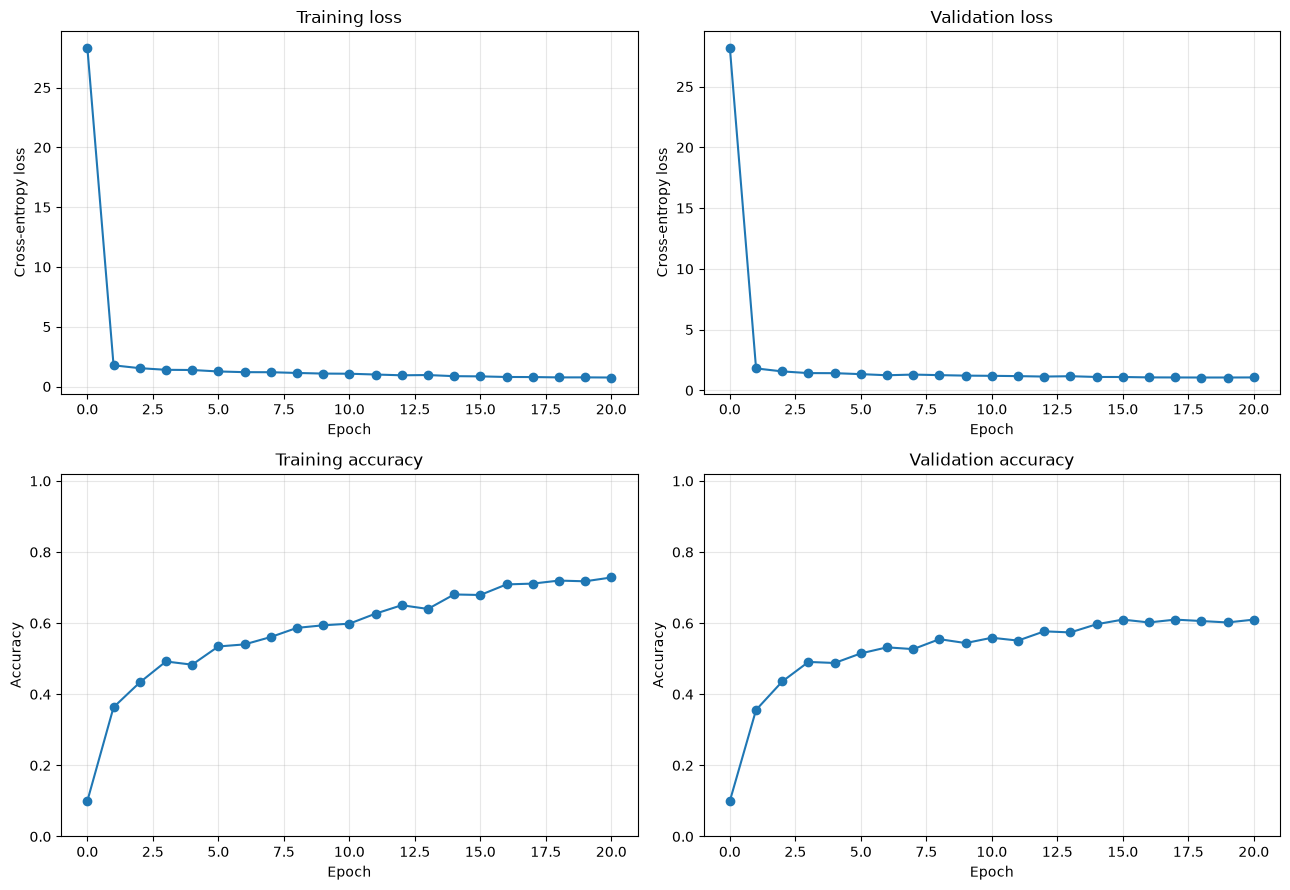

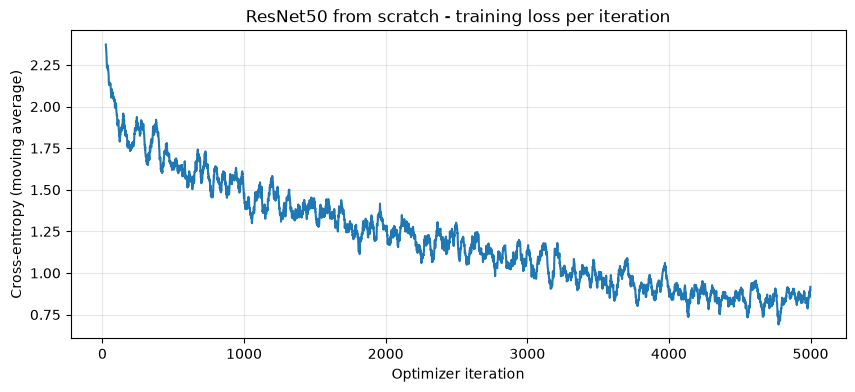

Final training accuracy: 72.85%
Final validation accuracy: 61.00%
Epoch  0, layer1 : (500, 256)


/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Epoch  0, layer2 : (500, 512)


/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Epoch  0, layer3 : (500, 1024)


/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


... (39 outputs left out)

/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Epoch 20, avgpool: (500, 2048)


/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Loaded/Generated 24 UMAP projections


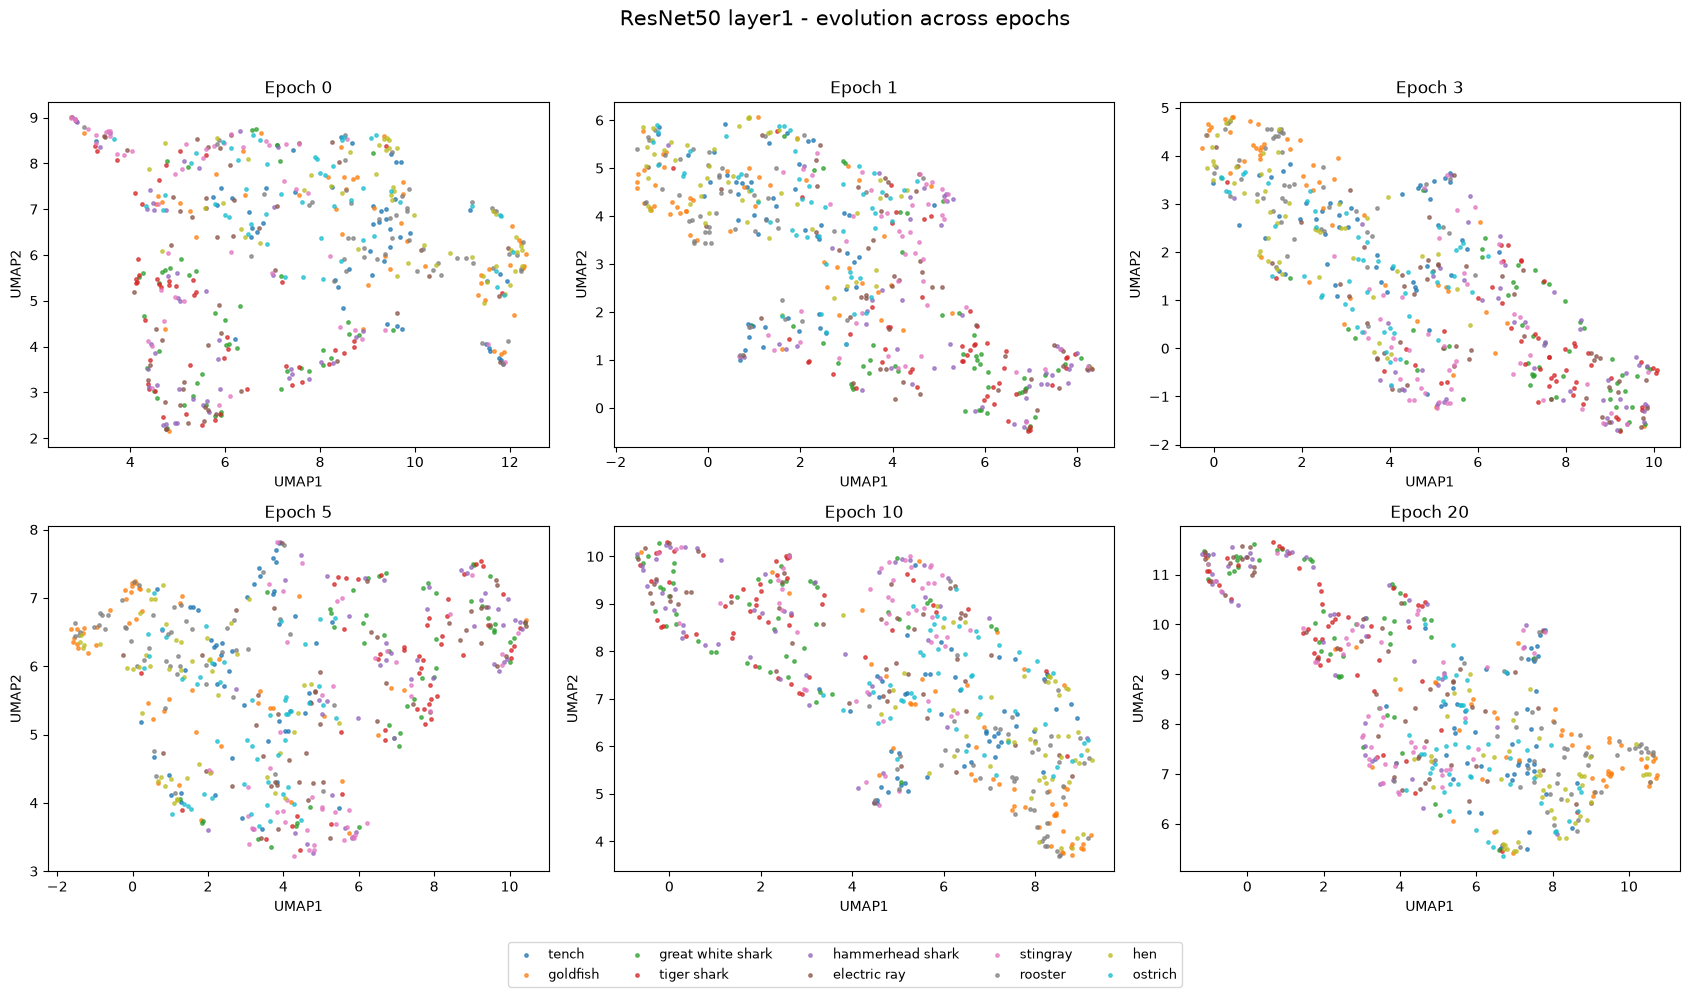

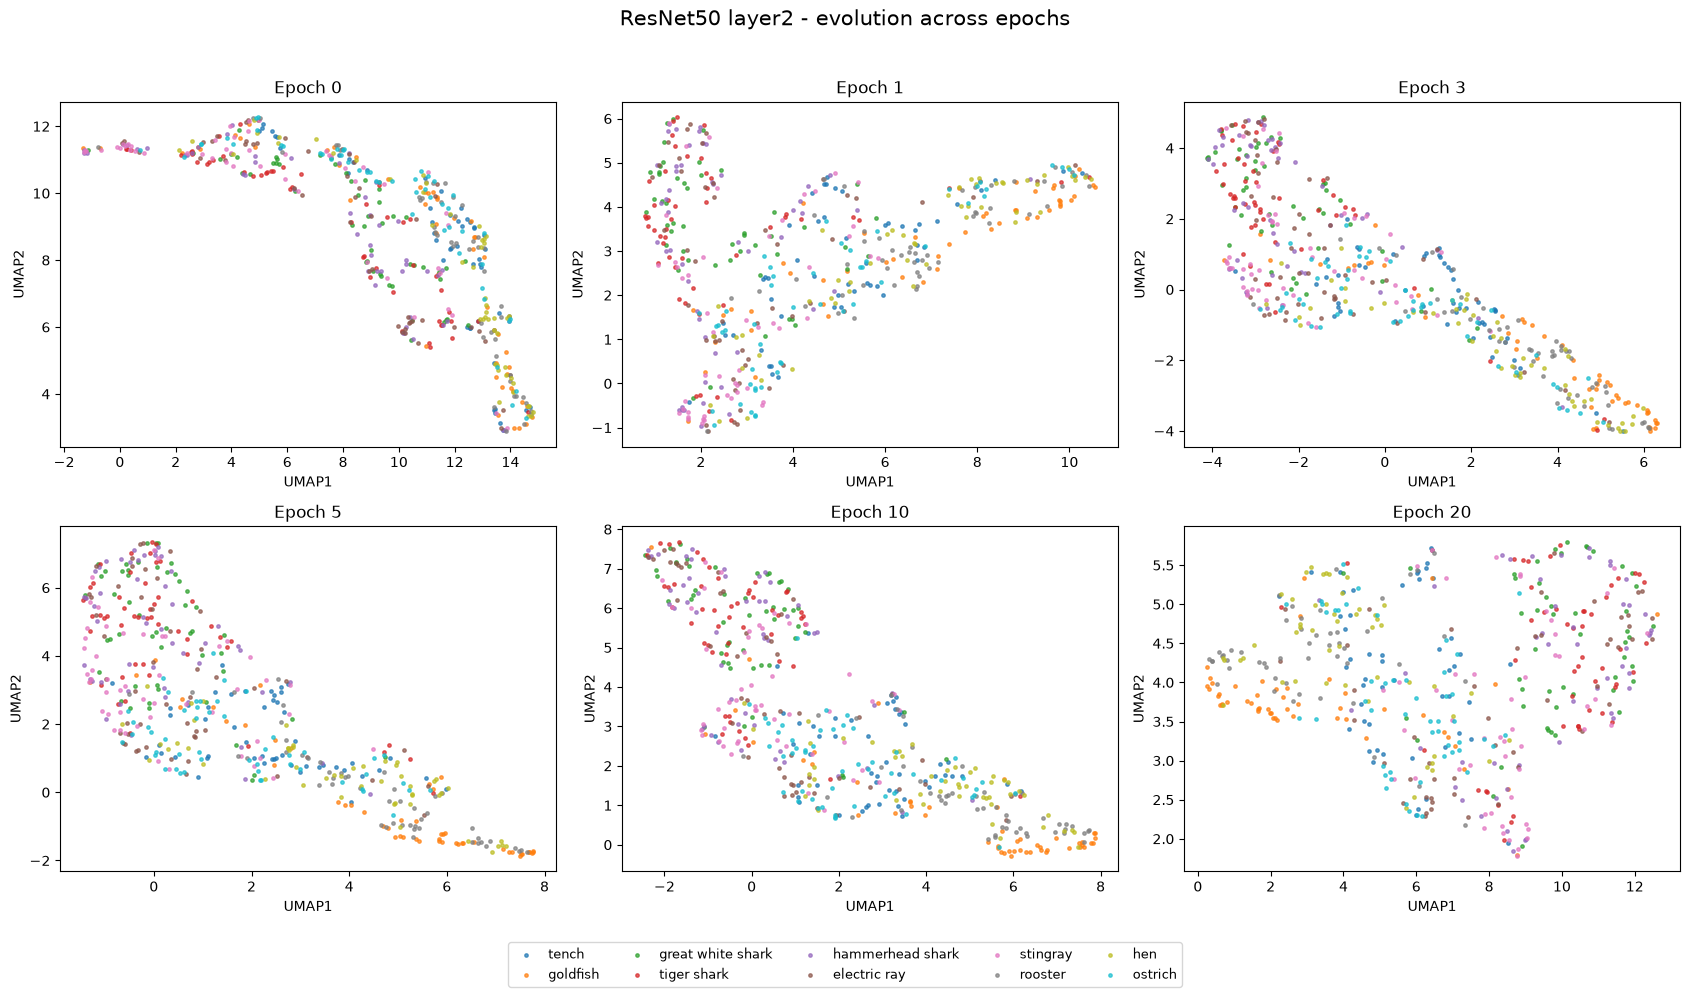

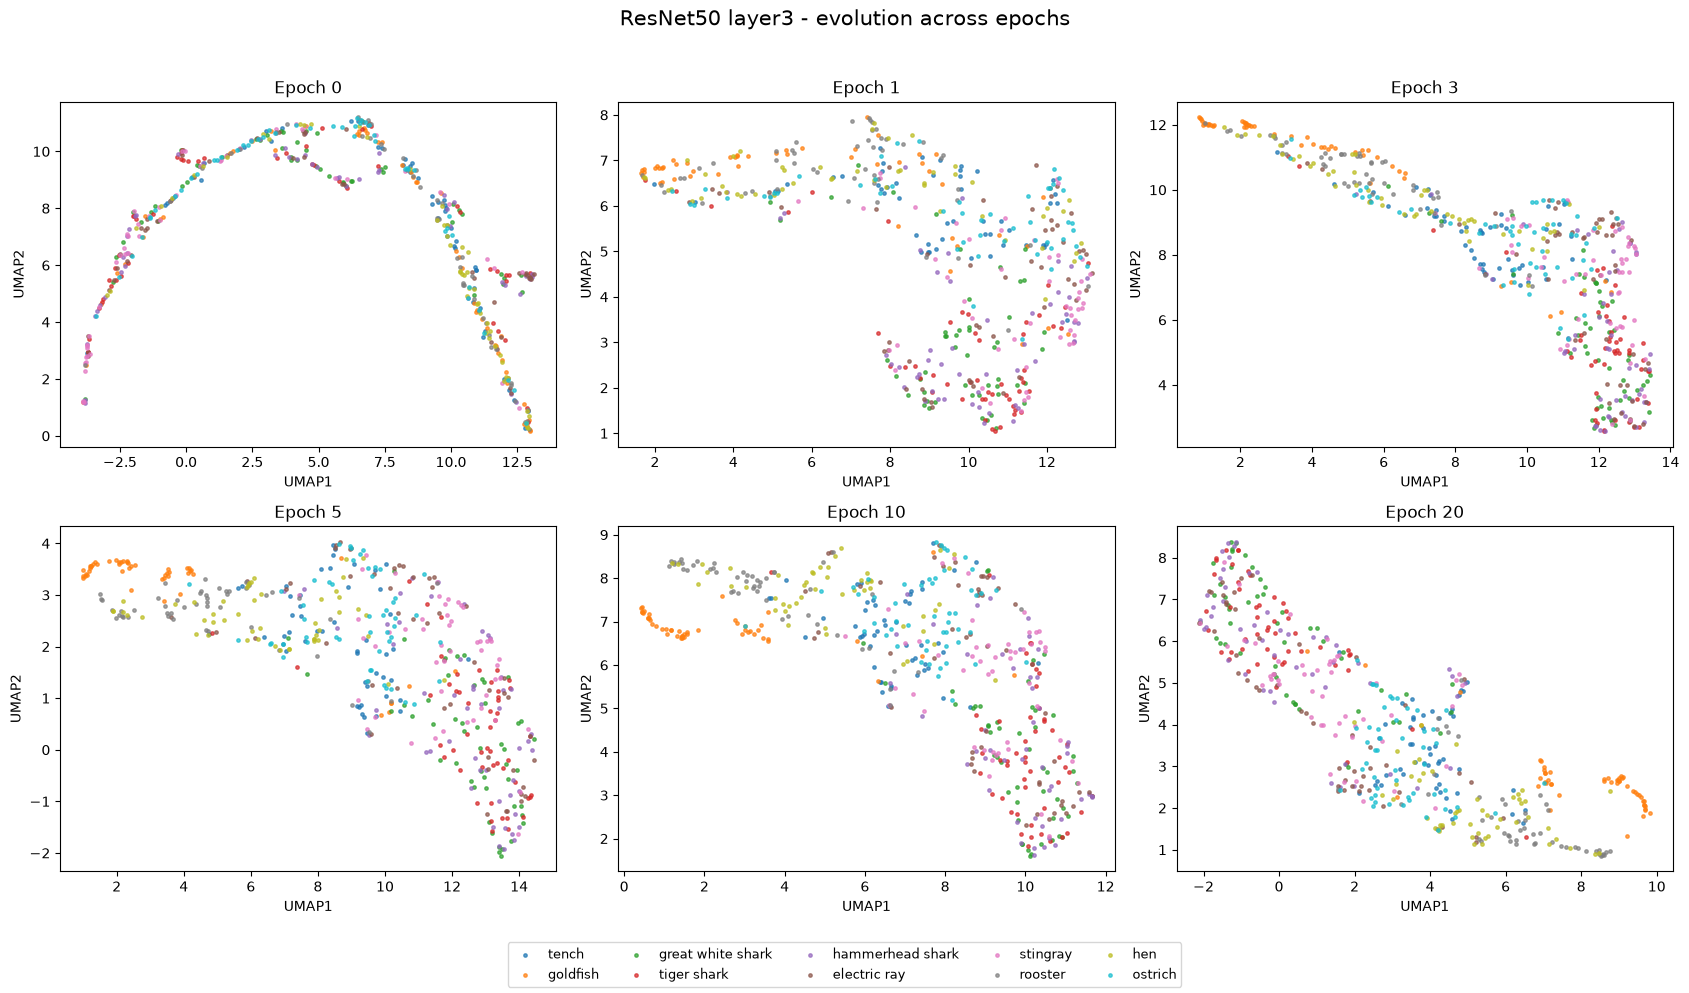

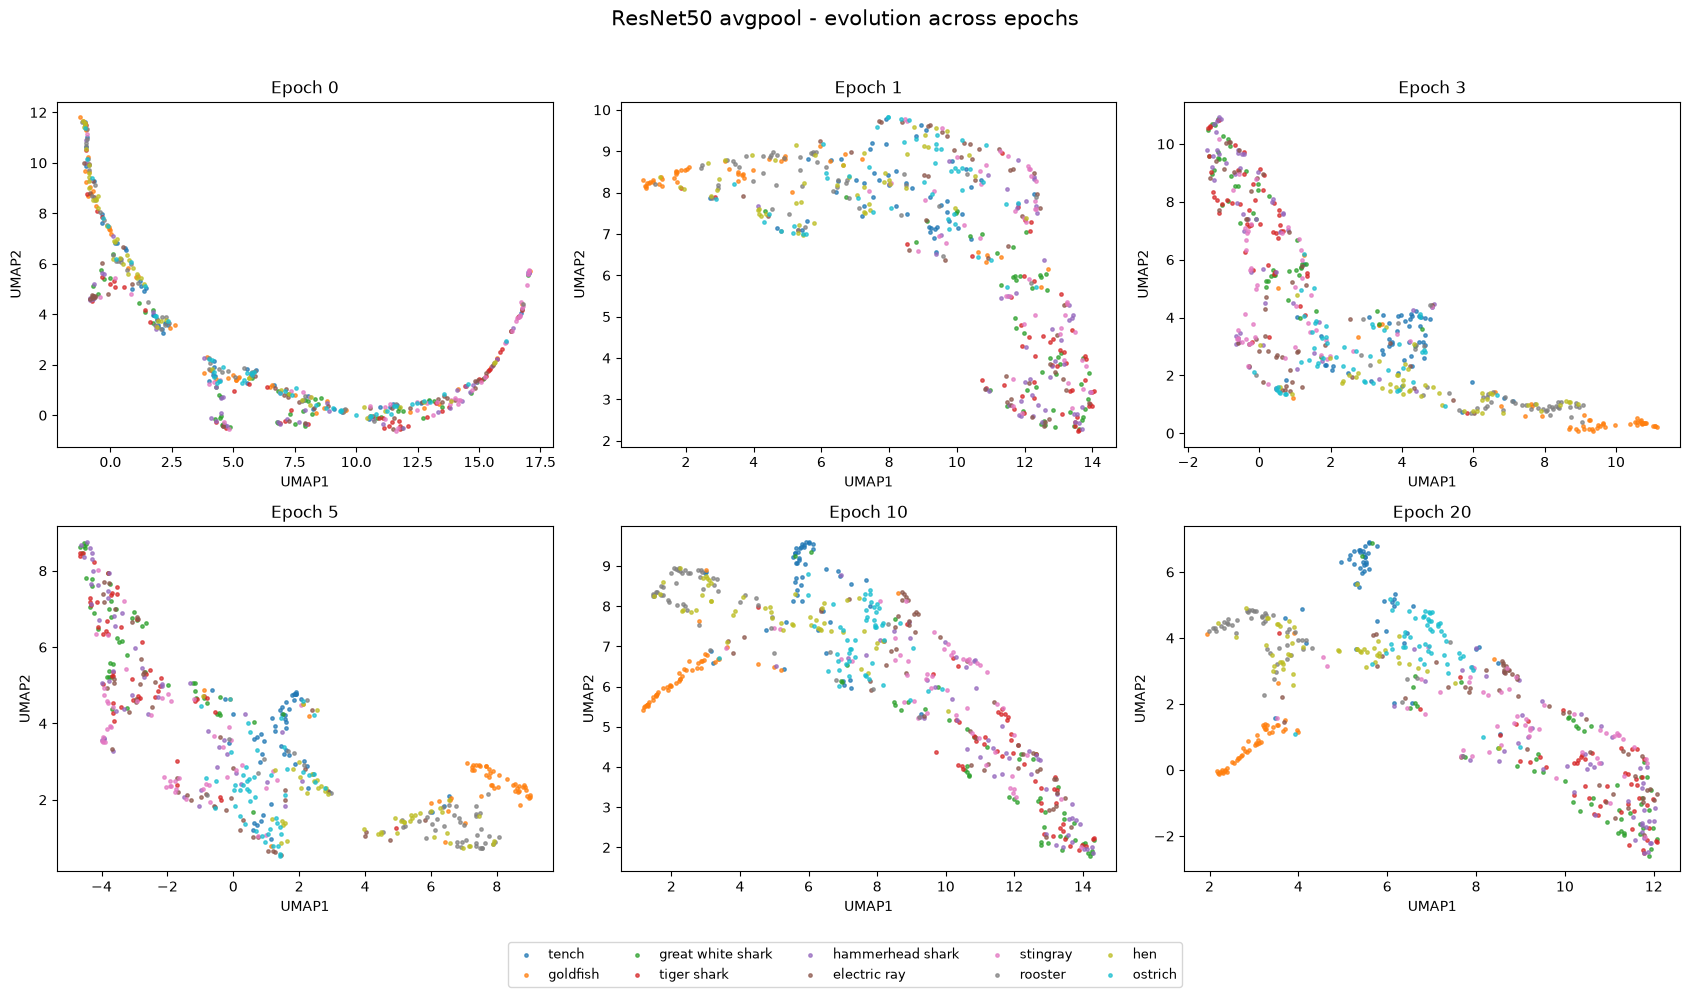

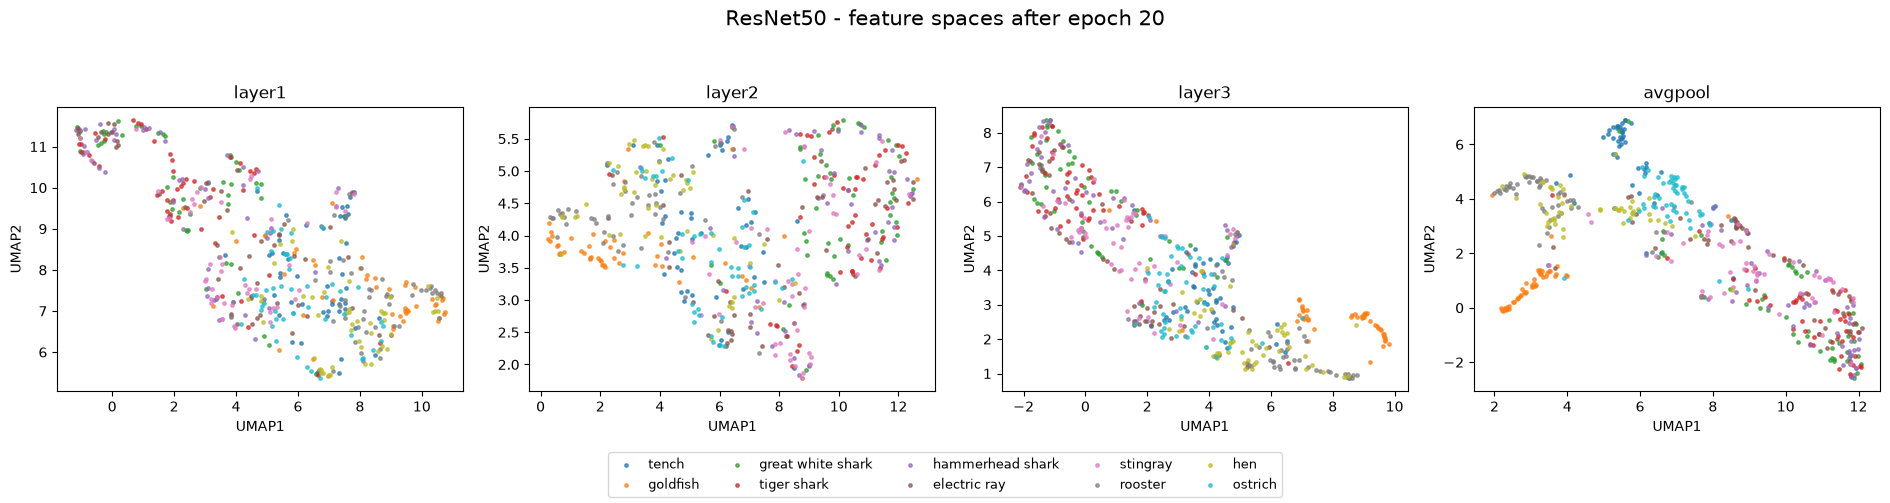

/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


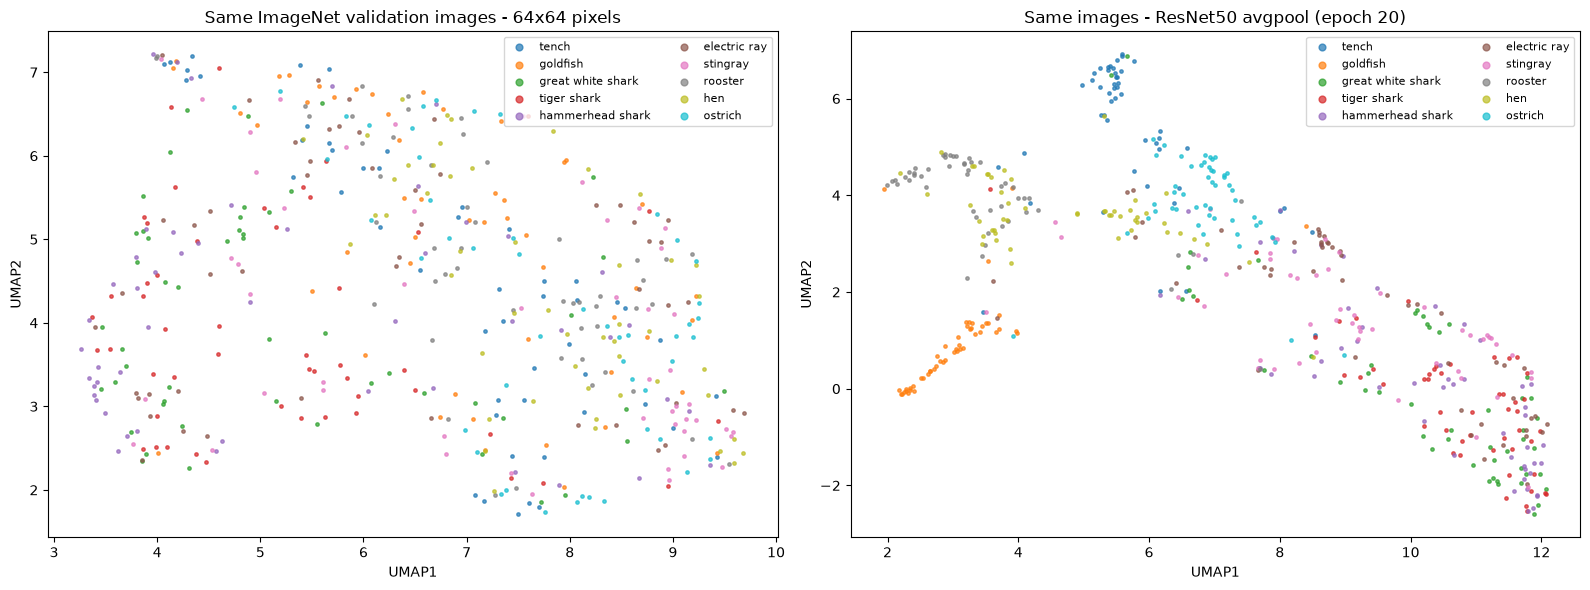

In [19]:
# Experiment 3

# Setup and dataset split

from pathlib import Path
import json

R50_IMAGE_SIZE = 224
R50_TRAIN_PER_CLASS = 400
R50_VAL_PER_CLASS = 100
R50_UMAP_PER_CLASS = 50
R50_BATCH_SIZE = 16
R50_EPOCHS = 20
R50_LR = 1e-4
R50_WEIGHT_DECAY = 1e-4
R50_CHECKPOINTS = sorted({e for e in (0, 1, 3, 5, 10, R50_EPOCHS) if e <= R50_EPOCHS})
R50_STAGES = ("layer1", "layer2", "layer3", "avgpool")

# Saving model parameters and UMAP projections to avoid repeat calculations:
# this is where they all go
R50_OUT_DIR = Path("./resne50_imagenet10_results")
R50_OUT_DIR.mkdir(parents=True, exist_ok=True)


r50_mean = [0.485, 0.456, 0.406]
r50_std = [0.229, 0.224, 0.225]
r50_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(R50_IMAGE_SIZE, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=r50_mean, std=r50_std),
])
r50_eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(R50_IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=r50_mean, std=r50_std)
])

# Same as Experiment 0 but with different transforms
r50_train_source = datasets.ImageFolder(imagenet.root, transform=r50_train_transform)
r50_eval_source = datasets.ImageFolder(imagenet.root, transform=r50_eval_transform)

r50_targets = np.asarray(imagenet.targets)
r50_rng = np.random.default_rng(SEED)
r50_train_ids, r50_val_ids = [], []
for cls in CLASS_IDS:
    candidates = r50_rng.permutation(np.flatnonzero(r50_targets == cls))
    required = R50_TRAIN_PER_CLASS + R50_VAL_PER_CLASS
    if len(candidates) < required:
        raise ValueError(f"Class {cls} contains {len(candidates)} images, need {required}")
    r50_train_ids.extend(candidates[:R50_TRAIN_PER_CLASS].tolist())
    r50_val_ids.extend(candidates[R50_TRAIN_PER_CLASS:required].tolist())
r50_rng.shuffle(r50_train_ids)
r50_rng.shuffle(r50_val_ids)

r50_train_dataset = Subset(r50_train_source, r50_train_ids)
r50_train_eval_dataset = Subset(r50_eval_source, r50_train_ids)
r50_val_dataset = Subset(r50_eval_source, r50_val_ids)

# Fix the same examples for all UMAP projections
r50_umap_ids = []
for cls in CLASS_IDS:
    class_val_ids = np.asarray(r50_val_ids)[r50_targets[r50_val_ids] == cls]
    r50_umap_ids.extend(r50_rng.choice(class_val_ids, R50_UMAP_PER_CLASS, replace=False).tolist())
r50_rng.shuffle(r50_umap_ids)
r50_umap_labels = r50_targets[r50_umap_ids]
r50_umap_dataset = Subset(r50_eval_source, r50_umap_ids)

r50_loader_options = dict(batch_size=R50_BATCH_SIZE, num_workers=2, pin_memory=(device.type=="cuda"))
r50_train_loader = DataLoader(r50_train_dataset, shuffle=True, generator=torch.Generator().manual_seed(SEED), **r50_loader_options)
r50_train_eval_loader = DataLoader(r50_train_eval_dataset, shuffle=False, **r50_loader_options)
r50_val_loader = DataLoader(r50_val_dataset, shuffle=False, **r50_loader_options)
r50_umap_loader = DataLoader(r50_umap_dataset, shuffle=False, **r50_loader_options)

print("ResNet50 training:", len(r50_train_dataset), "images")
print("ResNet50 validation:", len(r50_val_dataset), "images")
print("UMAP images:", len(r50_umap_dataset))
print("UMAP class distribution:", np.bincount(r50_umap_labels, minlength=10))
print("Device:", device)



# ResNet50 training, initialized from scratch
def r50_make_model():
    net = models.resnet50(weights=None)
    net.fc = nn.Linear(net.fc.in_features, len(CLASS_IDS))
    return net.to(device)

def r50_checkpoint_path(epoch):
    return R50_OUT_DIR / f"weights_epoch_{epoch:03d}.pt"


def r50_train_model():
    torch.manual_seed(SEED)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(SEED)
    net = r50_make_model()
    optimizer = torch.optim.AdamW(net.parameters(), lr=R50_LR, weight_decay=R50_WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=R50_EPOCHS)
    scaler = torch.amp.GradScaler("cuda", enabled=(device.type=="cuda"))
    loss_fn = nn.CrossEntropyLoss()
    hist = {"epoch": [], "train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "batch_loss": []}
    for epoch in range(R50_EPOCHS + 1):
        if epoch > 0:
            net.train()
            for images, labels in r50_train_loader:
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(device_type=device.type, enabled=(device.type=="cuda")):
                    logits = net(images)
                    loss = loss_fn(logits, labels)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                hist["batch_loss"].append(float(loss.item()))
            scheduler.step()
        train_loss, train_acc = evaluate_resnet(net, r50_train_eval_loader)
        val_loss, val_acc = evaluate_resnet(net, r50_val_loader)
        hist["epoch"].append(epoch)
        hist["train_loss"].append(train_loss)
        hist["train_acc"].append(train_acc)
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)
        # Save model state for each checkpoint
        if epoch in R50_CHECKPOINTS:
            torch.save(net.state_dict(), r50_checkpoint_path(epoch))
        (R50_OUT_DIR / "history.json").write_text(json.dumps(hist, indent=2))
        print(f"Epoch {epoch:2d}/{R50_EPOCHS} | "
              f"train loss {train_loss:.4f}, acc {train_acc:.2%} | "
              f"val loss {val_loss:.4f}, acc {val_acc:.2%}")
    return net, hist

# Reload result if already ran
r50_history_file = R50_OUT_DIR / "history.json"
if r50_history_file.exists() and r50_checkpoint_path(R50_EPOCHS).exists():
    r50_history = json.loads(r50_history_file.read_text())
    if r50_history["epoch"][-1] != R50_EPOCHS:
        raise ValueError("Saved history has a different epoch count; check R50_OUT_DIR")
    r50_model = r50_make_model()
    r50_model.load_state_dict(torch.load(r50_checkpoint_path(R50_EPOCHS), map_location=device, weights_only=True))
    print("Loaded existing ResNet50 weights and metrics from", R50_OUT_DIR)
else:
    r50_model, r50_history = r50_train_model()
    print("Trained fresh ResNet50 from scratch")



# Plot loss and accuracy
fig, axes = plt.subplots(2, 2, figsize=(13,9))
for ax, field, title in zip(axes.flat, ("train_loss", "val_loss", "train_acc", "val_acc"), ("Training loss", "Validation loss", "Training accuracy", "Validation accuracy")):
    ax.plot(r50_history["epoch"], r50_history[field], marker="o")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy" if "acc" in field else "Cross-entropy loss")
    ax.grid(alpha=0.3)
    if "acc" in field:
        ax.set_ylim(0, 1.02)
fig.tight_layout()
plt.show()

r50_batch_losses = np.asarray(r50_history["batch_loss"])
if len(r50_batch_losses):
    window = min(25, len(r50_batch_losses))
    smoothed = np.convolve(r50_batch_losses, np.ones(window) / window, mode="valid")
    plt.figure(figsize=(10, 4))
    plt.plot(np.arange(window - 1, len(r50_batch_losses)), smoothed)
    plt.xlabel("Optimizer iteration")
    plt.ylabel("Cross-entropy (moving average)")
    plt.title("ResNet50 from scratch - training loss per iteration")
    plt.grid(alpha=0.3)
    plt.show()
print(f"Final training accuracy: {r50_history['train_acc'][-1]:.2%}")
print(f"Final validation accuracy: {r50_history['val_acc'][-1]:.2%}")


# Extract features and run UMAP
@torch.inference_mode()
def r50_extract_stage_features(net, loader):
    net.eval()
    features = {stage: [] for stage in R50_STAGES}
    labels_all = []
    handles = []

    def make_hook(stage):
        def capture(module, inputs, output):
            # Pool intermediate feature maps down to one vector per image
            vectors = torch.nn.functional.adaptive_avg_pool2d(output, (1,1)).flatten(1)
            features[stage].append(vectors.detach().float().cpu().numpy())
        return capture

    for stage in R50_STAGES:
        handles.append(getattr(net, stage).register_forward_hook(make_hook(stage)))
    try:
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=(device.type=="cuda")):
                net(images)
            labels_all.append(labels.numpy())
    finally:
        for handle in handles:
            handle.remove()
    return ({stage: np.concatenate(features[stage]).astype(np.float32) for stage in R50_STAGES}, np.concatenate(labels_all))


r50_embeddings = {}
r50_feature_model = r50_make_model()
for epoch in R50_CHECKPOINTS:
    # Load cached UMAP results if they exist
    missing = []
    for stage in R50_STAGES:
        cache_path = R50_OUT_DIR / f"umap_e{epoch:03d}_{stage}.npy"
        if cache_path.exists():
            r50_embeddings[(epoch, stage)] = np.load(cache_path)
        else:
            missing.append(stage)
    if not missing:
        print(f"Epoch {epoch}: loaded cached UMAP results")
        continue
    weights_file = r50_checkpoint_path(epoch)
    if not weights_file.exists():
        raise FileNotFoundError(f"Checkpoint {weights_file} not found: train first")
    r50_feature_model.load_state_dict(torch.load(weights_file, map_location=device, weights_only=True))
    stage_features, feature_labels = r50_extract_stage_features(r50_feature_model, r50_umap_loader)
    for stage in missing:
        print(f"Epoch {epoch:2d}, {stage:7s}: {stage_features[stage].shape}")
        projection = run_umap(stage_features[stage], seed=SEED)
        r50_embeddings[(epoch, stage)] = projection
        np.save(R50_OUT_DIR / f"umap_e{epoch:03d}_{stage}.npy", projection)
    
print("Loaded/Generated", len(r50_embeddings), "UMAP projections")


# Visualize evolution and network depth
for stage in R50_STAGES:
    ncols = 3
    nrows = (len(R50_STAGES) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(17, 5*nrows), squeeze=False)
    for ax, epoch in zip(axes.flat, R50_CHECKPOINTS):
        plot_umap(r50_embeddings[(epoch, stage)], r50_umap_labels, imagenet_names, f"Epoch {epoch}", ax)
        ax.get_legend().remove() # One shared legend below all subplots
    for ax in list(axes.flat)[len(R50_CHECKPOINTS):]:
        ax.set_visible(False)
    legend_handles, legend_lables = axes.flat[0].get_legend_handles_labels()
    fig.legend(legend_handles, legend_lables, loc="lower center", ncol=5, fontsize=9)
    fig.suptitle(f"ResNet50 {stage} - evolution across epochs", fontsize=15)
    fig.tight_layout(rect=(0, 0.06, 1, 0.96))
    plt.show()

# One comparison across depth at the final epoch
fig, axes = plt.subplots(1, len(R50_STAGES), figsize=(19,5))
for ax, stage in zip(axes, R50_STAGES):
    plot_umap(r50_embeddings[(R50_EPOCHS, stage)], r50_umap_labels, imagenet_names, stage, ax)
    ax.get_legend().remove()
legend_handles, legend_lables = axes[0].get_legend_handles_labels()
fig.legend(legend_handles, legend_lables, loc="lower center", ncol=5, fontsize=9)
fig.suptitle(f"ResNet50 - feature spaces after epoch {R50_EPOCHS}", fontsize=15)
fig.tight_layout(rect=(0, 0.10, 1, 0.93))
plt.show()

# Compare these UMAPS with UMAP from Experiment 0
r50_raw_pixel_subset = Subset(imagenet, r50_umap_ids)
r50_raw_x, r50_raw_labels = extract_pixels(r50_raw_pixel_subset)

r50_pixel_cache = R50_OUT_DIR / "umap_same_val_pixels_64.npy"
if r50_pixel_cache.exists():
    r50_pixel_embedding = np.load(r50_pixel_cache)
else:
    r50_pixel_embedding = run_umap(r50_raw_x, seed=SEED)
    np.save(r50_pixel_cache, r50_pixel_embedding)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_umap(r50_pixel_embedding, r50_umap_labels, imagenet_names, "Same ImageNet validation images - 64x64 pixels", axes[0])
plot_umap(r50_embeddings[(R50_EPOCHS, "avgpool")], r50_umap_labels, imagenet_names, f"Same images - ResNet50 avgpool (epoch {R50_EPOCHS})", axes[1])
fig.tight_layout()
plt.show()

# Expérience 3

Comparé à la projection UMAP de l'espace des pixels à l'Expérience 0, la dernière représentation intermédiaire du réseau ResNet50 est beaucoup plus structurée. Certaines classes forment des groupes distincts (comme 'goldfish', 'tench' ou les espèces d'oiseaux), démontrant que le réseau a appris des représentations creusant les différences entre ces classes, aidant à la classification. Cepdenant, d'autres classes restent superposées, notamment les espèces de raies et de requins: étant donné que ces espèces sont visuellement assez similaires, ce n'est que peu surprenant. Cette difficulté se retrouve dans la performance du réseau, avec une accuracy d'entraînement de 72.85% et une accuracy de validation de 61%. Avec ce score de validation, nous pouvons remarquer que le réseau généralise plutôt mal, tandis que le score à l'entraînement indique que le modèle n'a pas entièrement appris à différencier toutes les classes. 

/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


SpiralNet independent test accuracy: 92.67%


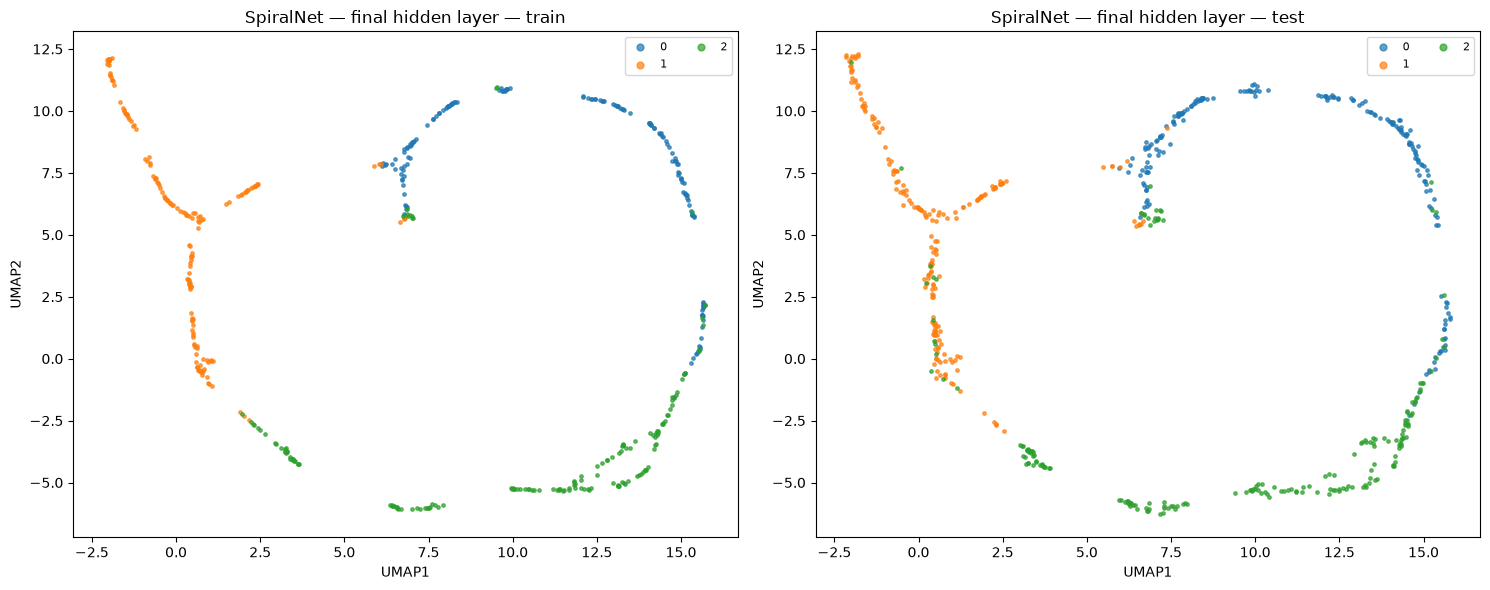

ResNet18 (Random initialization) — official MNIST test: loss=0.0425, accuracy=98.71%


/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


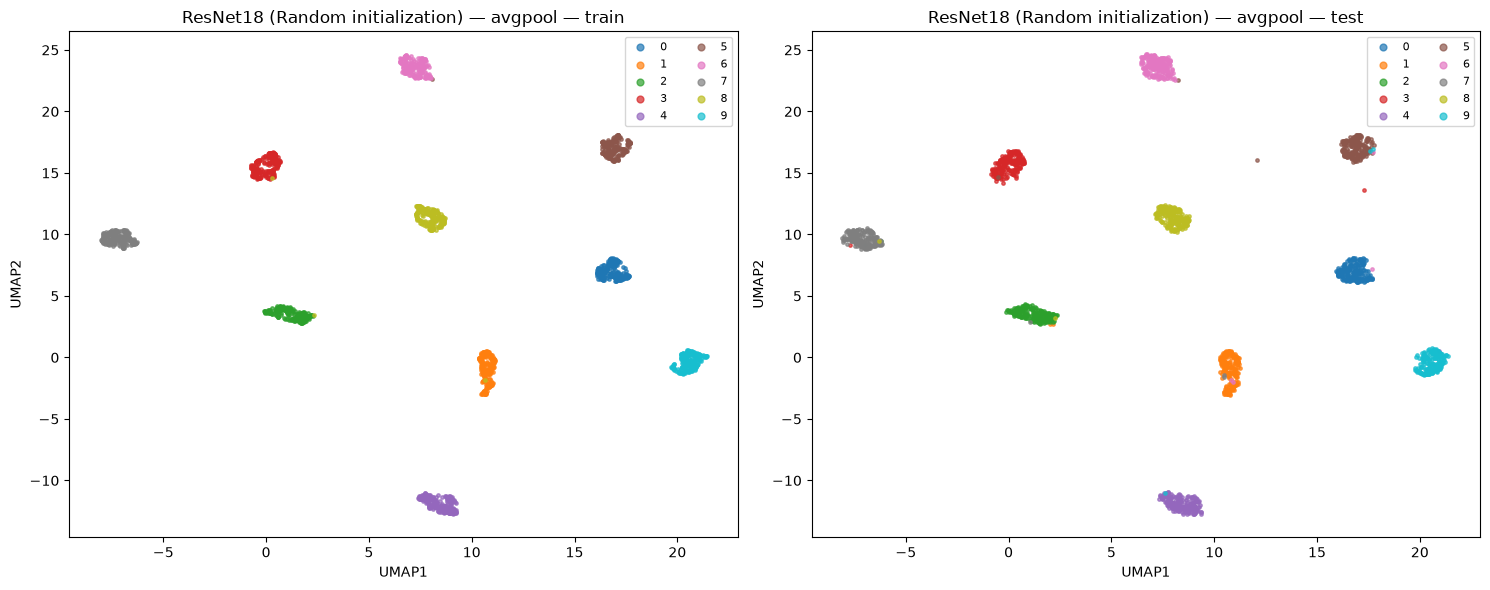

ResNet18 (ImageNet pretraining) — official MNIST test: loss=0.0413, accuracy=98.84%


/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


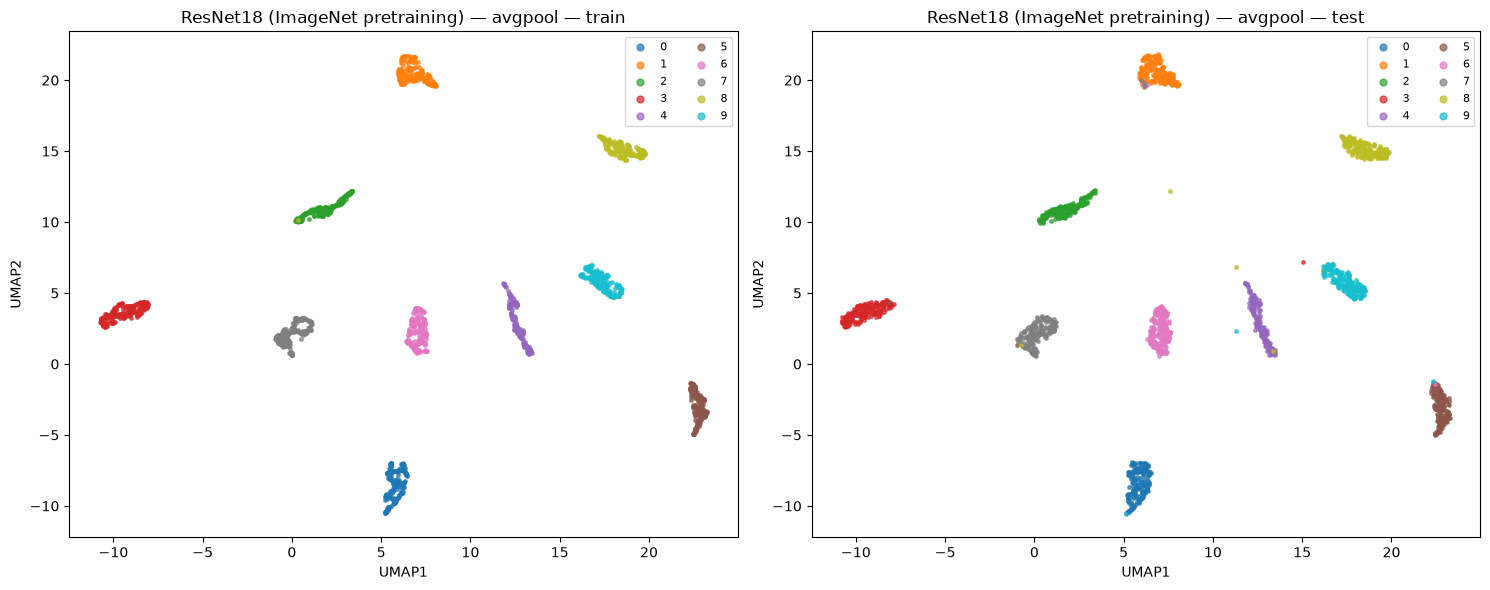

In [20]:
# Experiment 4


# Fit UMAP on TRAINING features, then transform TEST features
# This ensures both projections share the same coordinate system
def exp4_compare_umap(train_2d, test_2d, train_labels,
                      test_labels, names, title):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    plot_umap(
        train_2d, train_labels, names,
        f"{title} — train", axes[0]
    )
    plot_umap(
        test_2d, test_labels, names,
        f"{title} — test", axes[1]
    )

    # Use identical axis limits for both plots.
    combined = np.vstack([train_2d, test_2d])
    margins = np.maximum(np.ptp(combined, axis=0) * 0.05, 0.1)

    for ax in axes:
        ax.set_xlim(
            combined[:, 0].min() - margins[0],
            combined[:, 0].max() + margins[0]
        )
        ax.set_ylim(
            combined[:, 1].min() - margins[1],
            combined[:, 1].max() + margins[1]
        )

    fig.tight_layout()
    plt.show()


# ============================================================
# Experiment 1 — SpiralNet
# ============================================================

# toy_spiral3() resets its random seed internally.
# Calling it again would reproduce the original dataset.
# Generate an independent test dataset using the same formula.

exp4_rng = np.random.default_rng(SEED + 123)

exp4_spiral_X_parts = []
exp4_spiral_y_parts = []

EXP4_SPIRAL_TEST_PER_CLASS = 200

for cls in range(3):
    r = np.linspace(0.0, 1.0, EXP4_SPIRAL_TEST_PER_CLASS)

    theta = (
        5
        + np.linspace(
            cls * 4, (cls + 1) * 4,
            EXP4_SPIRAL_TEST_PER_CLASS
        )
        + exp4_rng.normal(
            0, 0.3, EXP4_SPIRAL_TEST_PER_CLASS
        )
    )

    exp4_spiral_X_parts.append(
        np.column_stack([
            r * np.sin(theta),
            r * np.cos(theta)
        ])
    )

    exp4_spiral_y_parts.append(
        np.full(EXP4_SPIRAL_TEST_PER_CLASS, cls)
    )

exp4_spiral_test_X = np.vstack(
    exp4_spiral_X_parts
).astype(np.float32)

exp4_spiral_test_y = np.concatenate(
    exp4_spiral_y_parts
)

exp4_spiral_test_tensor = torch.tensor(
    exp4_spiral_test_X,
    device=device
)

# Extract features from the trained SpiralNet.
model.eval()

with torch.inference_mode():
    exp4_spiral_train_features = model.project(
        X_train, N_HIDDEN
    ).cpu().numpy()

    exp4_spiral_test_features = model.project(
        exp4_spiral_test_tensor, N_HIDDEN
    ).cpu().numpy()

    exp4_spiral_test_pred = model(
        exp4_spiral_test_tensor
    ).argmax(1).cpu().numpy()

# Fit UMAP on training representations only.
exp4_spiral_umap = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    metric="euclidean",
    random_state=SEED,
    low_memory=True
)

exp4_spiral_train_2d = exp4_spiral_umap.fit_transform(
    exp4_spiral_train_features
)

exp4_spiral_test_2d = exp4_spiral_umap.transform(
    exp4_spiral_test_features
)

print(
    "SpiralNet independent test accuracy:",
    f"{np.mean(exp4_spiral_test_pred == exp4_spiral_test_y):.2%}"
)

exp4_compare_umap(
    exp4_spiral_train_2d,
    exp4_spiral_test_2d,
    y_train.cpu().numpy(),
    exp4_spiral_test_y,
    ["0", "1", "2"],
    "SpiralNet — final hidden layer"
)


# ============================================================
# Experiment 2 — ResNet18 (both versions)
# ============================================================

# Official MNIST test set.
# Reuse Experiment 2's exact preprocessing.
exp4_mnist_test = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=resnet_transform
)

# Full test set for classification accuracy.
exp4_test_loader_full = DataLoader(
    exp4_mnist_test,
    batch_size=RESNET_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=resnet_pin
)

# Balanced test subset for UMAP (200 examples per class).
# The training UMAP features already exist from Experiment 2.
exp4_test_subset = balanced_subset(
    exp4_mnist_test,
    CLASS_IDS,
    RESNET_UMAP_PER_CLASS,
    seed=SEED + 1
)

exp4_test_umap_loader = DataLoader(
    exp4_test_subset,
    batch_size=RESNET_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=resnet_pin
)

# Compare both trained ResNet18 models.
for label, net, train_features, train_labels in [
    (
        "Random initialization",
        resnet_random_model,
        resnet_features_random,
        resnet_labels_random
    ),
    (
        "ImageNet pretraining",
        resnet_pretrained_model,
        resnet_features_pretrained,
        resnet_labels_pretrained
    )
]:
    # Evaluate on the entire official MNIST test split.
    test_loss, test_acc = evaluate_resnet(
        net, exp4_test_loader_full
    )

    print(
        f"ResNet18 ({label}) — official MNIST test:",
        f"loss={test_loss:.4f}, accuracy={test_acc:.2%}"
    )

    # Extract test features immediately before flattening.
    test_features, test_labels = resnet_avgpool_features(
        net, exp4_test_umap_loader
    )

    # Fit a separate UMAP on each model's TRAINING features.
    reducer = umap.UMAP(
        n_neighbors=15,
        min_dist=0.1,
        n_components=2,
        metric="euclidean",
        random_state=SEED,
        low_memory=True
    )

    train_2d = reducer.fit_transform(train_features)
    test_2d = reducer.transform(test_features)

    exp4_compare_umap(
        train_2d,
        test_2d,
        train_labels,
        test_labels,
        mnist_names,
        f"ResNet18 ({label}) — avgpool"
    )


# Expérience 4

Pour le jeu Spiral, les projections d'entraînement et de test sont similaires, mais celle de test est plus dispersée et irrégulière. De plus, son accuracy de 92% montre une généralisation correcte, mais imparfaite: on peut notamment remarquer, au centre de la figure, qu'il y a une superposition des trois classes. Elle devient d'autant plus visible avec le jeu de test.

Pour les deux réseaux ResNet18, les deux jeux montrent des projections UMAP quasiment identiques. Cela est principalement dû à la transformation que nous appliquons sur le jeu de test afin que les deux projections partagent le même système de coordonnées, mais nous aurions également eu une séparation très claire des clusters même sans cette transformation, comme nous avons pu le voir à l'Expérience 2.

Les modèles sont donc bien capables d'apprendre des représentations intermédiaires permettant de différencier les classes, et ces représentations restent efficaces même sur de nouvelles données tant que le modèle est suffisamment performant.

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 18.2M/18.2M [00:12<00:00, 1.48MB/s]
100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 29.5k/29.5k [00:00<00:00, 111kB/s]
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3.04M/3.04M [00:02<00:00, 1.02MB/s]
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5.12k/5.12k [00:00<00:00, 6.76MB/s]
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout

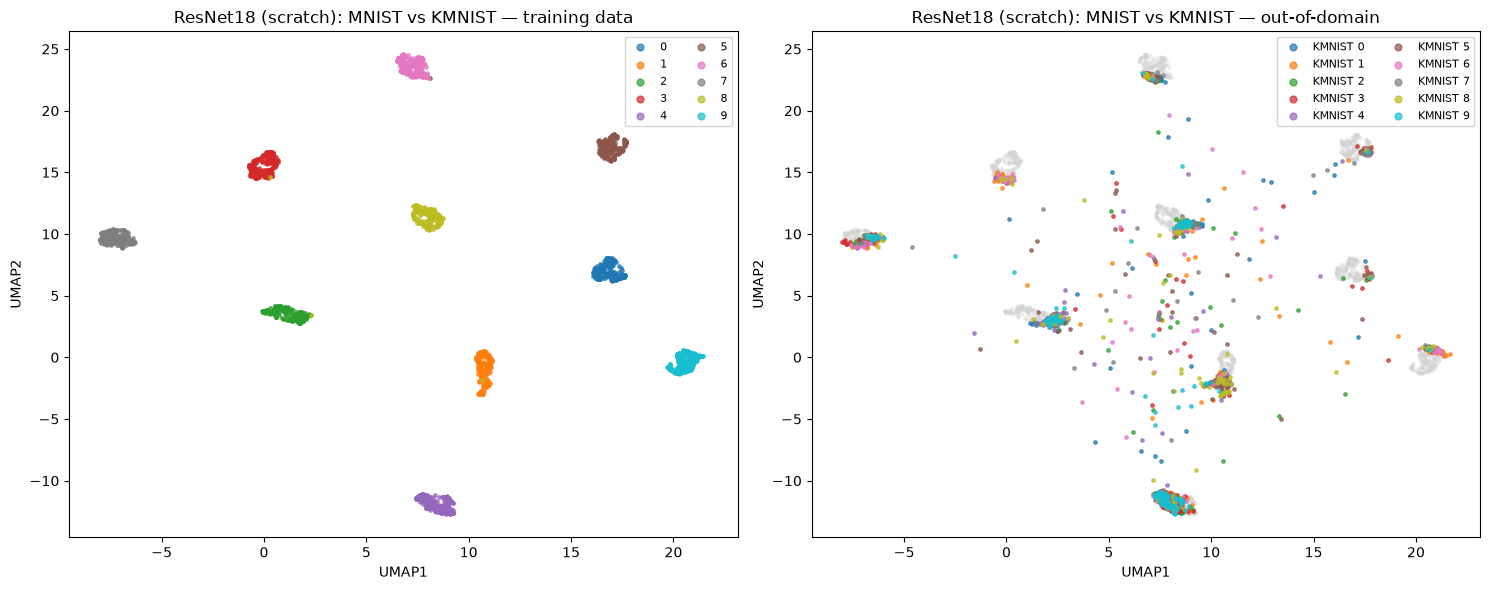

/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


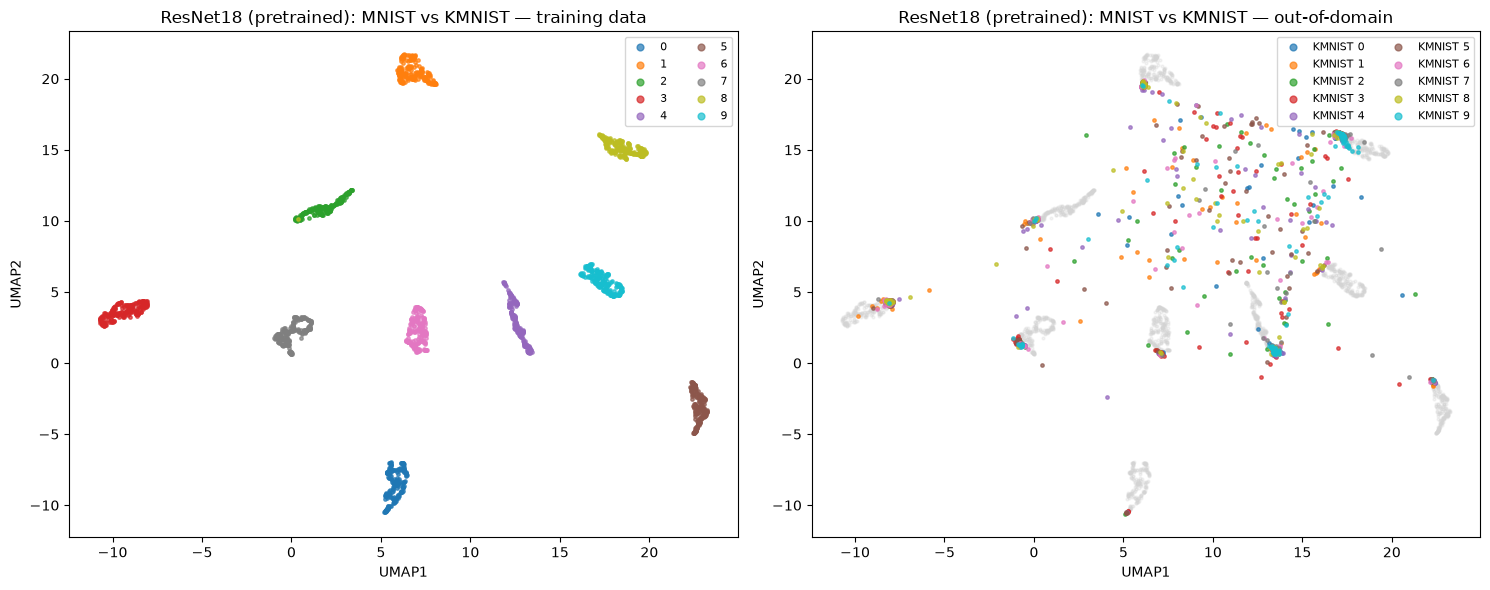

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 94.3M/94.3M [00:08<00:00, 11.7MB/s]
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


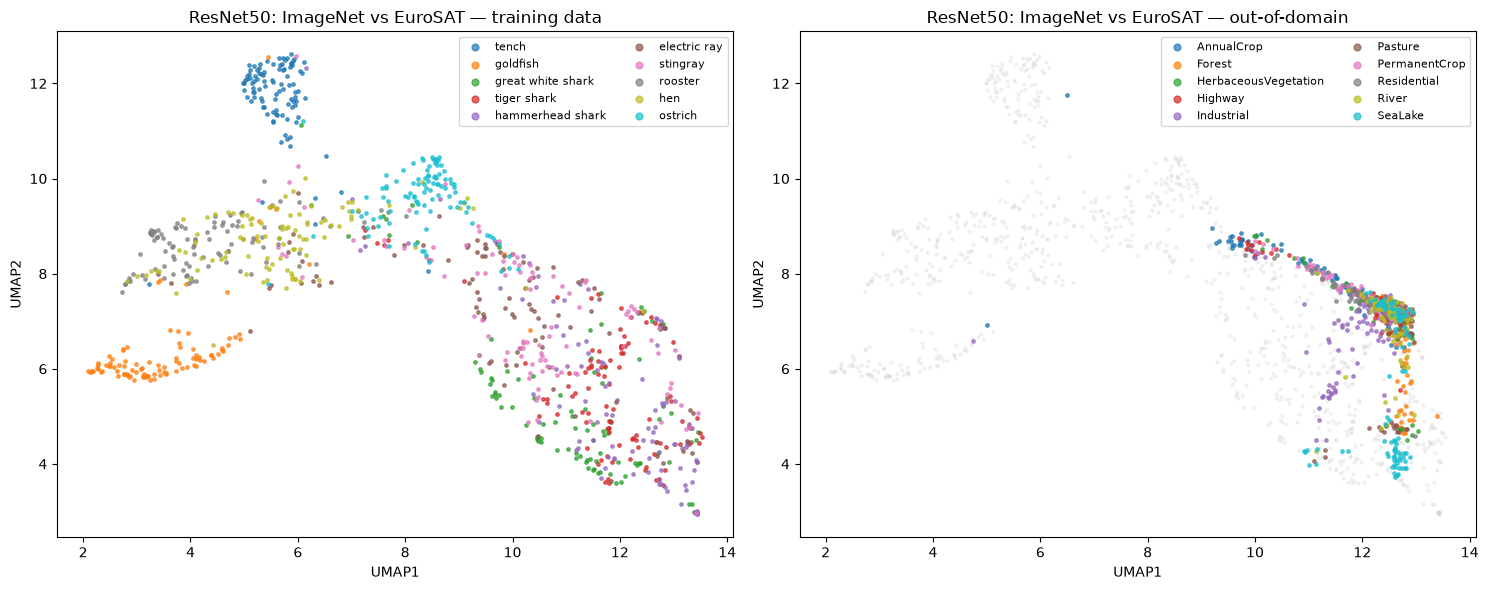

In [21]:
# Experiment 5

# Compare features using a UMAP fitted ONLY on training data.
def exp5_compare(train_features, train_labels,
                 ood_features, ood_labels,
                 train_names, ood_names, title):

    reducer = umap.UMAP(
        n_neighbors=15,
        min_dist=0.1,
        n_components=2,
        metric="euclidean",
        random_state=SEED,
        low_memory=True
    )

    train_xy = reducer.fit_transform(train_features)
    ood_xy = reducer.transform(ood_features)

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    plot_umap(
        train_xy, train_labels, train_names,
        f"{title} — training data", axes[0]
    )

    # Faint training points as spatial reference.
    axes[1].scatter(
        train_xy[:, 0], train_xy[:, 1],
        color="lightgray", s=4, alpha=0.25
    )

    plot_umap(
        ood_xy, ood_labels, ood_names,
        f"{title} — out-of-domain", axes[1]
    )

    # Same limits on both plots.
    combined = np.vstack([train_xy, ood_xy])
    margin = np.maximum(np.ptp(combined, axis=0) * 0.05, 0.1)

    for ax in axes:
        ax.set_xlim(combined[:, 0].min() - margin[0],
                    combined[:, 0].max() + margin[0])
        ax.set_ylim(combined[:, 1].min() - margin[1],
                    combined[:, 1].max() + margin[1])

    fig.tight_layout()
    plt.show()


# ==================================================
# Part A — MNIST-trained ResNet18 vs KMNIST
# ==================================================

# Reuse the exact MNIST preprocessing from Experiment 2.
exp5_kmnist = datasets.KMNIST(
    root="./data",
    train=False,
    download=True,
    transform=resnet_transform
)

# 200 images per KMNIST class.
exp5_kmnist_subset = balanced_subset(
    exp5_kmnist,
    CLASS_IDS,
    n_per_class=RESNET_UMAP_PER_CLASS,
    seed=SEED
)

exp5_kmnist_loader = DataLoader(
    exp5_kmnist_subset,
    batch_size=RESNET_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=resnet_pin
)

kmnist_names = [f"KMNIST {i}" for i in CLASS_IDS]

# Both versions of ResNet18 from Experiment 2.
for name, net, train_features, train_labels in [
    (
        "ResNet18 (scratch)",
        resnet_random_model,
        resnet_features_random,
        resnet_labels_random
    ),
    (
        "ResNet18 (pretrained)",
        resnet_pretrained_model,
        resnet_features_pretrained,
        resnet_labels_pretrained
    )
]:
    ood_features, ood_labels = resnet_avgpool_features(
        net, exp5_kmnist_loader
    )

    exp5_compare(
        train_features, train_labels,
        ood_features, ood_labels,
        mnist_names, kmnist_names,
        name + ": MNIST vs KMNIST"
    )


# ==================================================
# Part B — ImageNet-trained ResNet50 vs EuroSAT
# ==================================================

# Reuse ResNet50 preprocessing from Experiment 3.
exp5_eurosat = datasets.EuroSAT(
    root="./data",
    download=True,
    transform=r50_eval_transform
)

# 100 examples per EuroSAT class.
exp5_eurosat_subset = balanced_subset(
    exp5_eurosat,
    list(range(len(exp5_eurosat.classes))),
    n_per_class=100,
    seed=SEED
)

exp5_eurosat_loader = DataLoader(
    exp5_eurosat_subset,
    batch_size=R50_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# Select 100 original ImageNet TRAINING examples
# per class, using the training split from Experiment 3.
rng = np.random.default_rng(SEED)
train_ids = np.asarray(r50_train_ids)
exp5_imagenet_ids = []

for cls in CLASS_IDS:
    candidates = train_ids[r50_targets[train_ids] == cls]
    exp5_imagenet_ids.extend(
        rng.choice(candidates, size=100, replace=False).tolist()
    )

# Deterministic evaluation preprocessing, not augmentation.
exp5_imagenet_train_loader = DataLoader(
    Subset(r50_eval_source, exp5_imagenet_ids),
    batch_size=R50_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# Reuse the trained ResNet50 and the existing
# multi-stage feature extraction function.
with torch.inference_mode():
    train_stages, train_labels = r50_extract_stage_features(
        r50_model, exp5_imagenet_train_loader
    )

    ood_stages, ood_labels = r50_extract_stage_features(
        r50_model, exp5_eurosat_loader
    )

# Compare the representations immediately before flattening.
exp5_compare(
    train_stages["avgpool"], train_labels,
    ood_stages["avgpool"], ood_labels,
    imagenet_names, exp5_eurosat.classes,
    "ResNet50: ImageNet vs EuroSAT"
)


# Expérience 5

Pour le réseau ResNet18 sans pré-entraînement, les caractères de KMNIST sont largement distribués, et la plupart s'agrègent autour de clusters MNIST existant, tandis que beaucoup d'autres points se répartissent dans l'espace entre les clusters. Cependant, même si les points se rassemblent, leurs classes restent mélangées.

Pour le réseau ResNet18 avec pré-entraînement, les caractères de KMNIST sont beaucoup plus superposés et se concentrent dans la région autour des clusters MNIST 1, 8 et 9. La distribution générale des points diffèrent beaucoup du réseau sans pré-entraînement: bien que les deux modèles sont très performants sur MNIST, cette expérience démontre la différence de leurs représentations intermédiaires, entraînant de grandes différences sur des données hors-domaine.

Pour le réseau ResNet50 sur ImageNet, la grande majorité des images d'EuroSat se concentrent dans une région très limitée de la projection UMAP, là où se trouvaient les classes des raies et requins dans la projection UMAP sur ImageNet. 

Étant donné que ces modèles se sont entraînés sur des jeux de données différents que ceux introduits ici (surtout pour ResNet50), ces résultats sont compréhensibles. Bien que l'Expérience 4 ait démontré la capacité de généralisation des modèles au sein du même domaine, cette expérience démontre les limitations de cette généralisation en cas de changement de domaine. 